### Information Gain and Splitting Criteria

Understanding how trees choose the best splits is crucial for clinicians who need to trust and validate AI decisions.

In [1]:
# Core libraries for clinical AI applications
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, mean_squared_error, r2_score
from sklearn.tree import plot_tree, export_text
import warnings
warnings.filterwarnings('ignore')

# Visualization libraries
import matplotlib.patches as patches
from matplotlib.colors import ListedColormap

# Interactive widgets for exploration
from ipywidgets import interact, FloatSlider, IntSlider, Dropdown, SelectMultiple

# Try to import graphviz for tree visualization
try:
    import graphviz
    from sklearn.tree import export_graphviz
    GRAPHVIZ_AVAILABLE = True
    print("✅ Graphviz available for enhanced tree visualization")
except ImportError:
    GRAPHVIZ_AVAILABLE = False
    print("⚠️  Graphviz not available - using matplotlib for tree visualization")

# Set visualization style for professional clinical engineering context
plt.style.use('default')
sns.set_palette("viridis")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Version checks for reproducibility
import sklearn
print(f"\n🔧 Environment Setup Complete")
print(f"   📊 NumPy version: {np.__version__}")
print(f"   📈 Pandas version: {pd.__version__}")
print(f"   🤖 Scikit-learn version: {sklearn.__version__}")
print(f"   📊 Matplotlib version: {plt.matplotlib.__version__}")

print(f"\n🩺 Ready for clinical AI Workshop - Decision Trees & Ensemble Methods!")

✅ Graphviz available for enhanced tree visualization

🔧 Environment Setup Complete
   📊 NumPy version: 2.5.3
   📈 Pandas version: 3.0.6
   🤖 Scikit-learn version: 1.9.1
   📊 Matplotlib version: 3.11.2

🩺 Ready for clinical AI Workshop - Decision Trees & Ensemble Methods!


---
## 2. Single Decision Tree Fundamentals

Let's start with the foundation: understanding how a single decision tree makes decisions. We'll use a clinical example that's relevant to the workshop themes.

### clinical Example: Sepsis Triage Classification

Imagine you're developing an AI system to assist with navigation in a busy acute ward. The system needs to classify conditions as:
- **Safe**: Normal transit speed
- **Caution**: Reduced speed required
- **High Risk**: Avoid or proceed with extreme caution

The decision depends on multiple factors that a decision tree can learn to combine intelligently.

## 1. Introduction & Setup

Decision trees are fundamental to many clinical AI applications because they:
- **Make interpretable decisions**: Critical for safety-critical clinical systems
- **Handle mixed data types**: Numerical sensor readings + categorical conditions
- **Provide feature importance**: Identify which sensors/parameters matter most
- **Form the basis of powerful ensembles**: Random Forests and Gradient Boosting

### Why Trees Matter for Healthcare

**Sepsis Triage Example**: A decision tree might ask:
1. Is ice thickness > 0.5m? → If NO: Safe passage
2. Is Lactate above 4 mmol/L? → If YES: High risk
3. Is the patient over 75 with two or more comorbidities? → Determines safe speed

**Care Planning Example**: Tree-based models can support:
- Discharge pathway selection based on frailty and social support
- Escalation thresholds for a rapid response team
- Triage category assignment at the front door

Let's start by importing our libraries and setting up the environment:

# Decision Trees: From Basic Concepts to Ensemble Methods for Healthcare

## Workshop Module 2 | Clinical AI Learning Path

This notebook takes you from a single decision tree through to XGBoost, using three
clinical problems that build on one another:

| Section | Clinical problem | ML concept |
|---|---|---|
| 2-5 | **Sepsis triage risk** from admission vitals and labs | A single decision tree: splits, entropy, information gain, instability |
| 6 | **Ward escalation priority** from bedside monitoring | Random Forest: bagging, ensemble diversity, feature importance |
| 7 | **Length of stay** from admission characteristics | Gradient Boosting and XGBoost: sequential residual correction |

### Why decision trees matter in healthcare

A decision tree is one of the few model families a clinician can read directly. Every
prediction is a path of yes/no questions, which means a care team can see exactly why a
patient was flagged. That auditability is worth a great deal in a clinical setting, and it
is why trees and tree ensembles remain the workhorse of tabular clinical prediction.

> **About the data.** Every patient in this notebook is simulated from published
> physiological reference ranges. No real or identifiable patient data is used anywhere in
> this course.

---


In [2]:
# Generate realistic synthetic sepsis triage data
# This simulates vital signs and laboratory results recorded at admission
np.random.seed(42)  # For reproducible results in workshop

def generate_sepsis_triage_data(n_samples=1000):
    """
    Generate synthetic but realistic sepsis triage data.

    Features are the measurements a triage nurse or emergency clinician has in
    front of them within the first hour of a patient's arrival. All values are
    simulated from published reference ranges; no real patient data is used.
    """
    # Infection and inflammation markers (primary factors)
    temp_c = np.random.normal(37.2, 1.1, n_samples)          # Core temperature (deg C)
    wbc = np.random.gamma(4, 2.2, n_samples)                 # White cell count (10^9/L)
    lactate = np.random.gamma(2, 0.7, n_samples)             # Serum lactate (mmol/L)

    # Hemodynamic and respiratory observations
    heart_rate = np.random.normal(88, 18, n_samples)         # Heart rate (bpm)
    systolic_bp = np.random.normal(124, 20, n_samples)       # Systolic BP (mmHg)
    resp_rate = np.random.normal(18, 5, n_samples)           # Respiratory rate (breaths/min)

    # Patient characteristics
    age = np.random.normal(62, 18, n_samples)                # Age (years)

    # Create a realistic triage risk classification.
    # This stands in for the clinical judgement the tree will learn: a higher
    # stability score means a more reassuring presentation.
    stability_score = (
        -1.7 * (temp_c - 37.0) +          # Fever suggests infection
        -0.22 * (wbc - 7.5) +             # Leukocytosis suggests infection
        -1.6 * (lactate - 1.0) +          # Raised lactate means tissue hypoperfusion
        -0.055 * (heart_rate - 78) +      # Tachycardia is an early warning sign
        0.045 * (systolic_bp - 120) +     # Maintained blood pressure is reassuring
        -0.20 * (resp_rate - 16) +        # Tachypnoea is a strong deterioration signal
        -0.030 * (age - 60) +             # Older patients decompensate sooner
        np.random.normal(0, 0.6, n_samples)  # Individual variation
    )

    # Convert to the three triage categories used on the ward.
    # The cut-points are calibrated to a realistic emergency-department case mix:
    # most people who present are not septic. Getting this prevalence right matters -
    # a model trained on a case mix that never occurs will not transfer to the ward,
    # and accuracy on a balanced sample would badly overstate real performance.
    high_cut, watch_cut = np.quantile(stability_score, [0.12, 0.40])
    triage_risk = np.where(stability_score > watch_cut, 'Low Risk',
                          np.where(stability_score > high_cut, 'Watch', 'High Risk'))

    # Create DataFrame using standard clinical terminology
    data = pd.DataFrame({
        'temp_c': np.clip(temp_c, 34.0, 41.5),
        'wbc': np.clip(wbc, 1.0, 40.0),
        'lactate_mmol_l': np.clip(lactate, 0.3, 12.0),
        'heart_rate': np.clip(heart_rate, 40, 180),
        'systolic_bp': np.clip(systolic_bp, 60, 210),
        'resp_rate': np.clip(resp_rate, 6, 45),
        'age': np.clip(age, 18, 98).round().astype(int),
        'triage_risk': triage_risk
    })

    return data

# Generate our clinical dataset
triage_data = generate_sepsis_triage_data(1000)

print("🩺 Sepsis Triage Dataset Generated (simulated, no real patient data)")
print(f"📊 {len(triage_data)} patient presentations")
print(f"🎯 Triage Categories: {triage_data['triage_risk'].value_counts().to_dict()}")
print("\n📋 Sample of triage data:")
triage_data.head(10)


🩺 Sepsis Triage Dataset Generated (simulated, no real patient data)
📊 1000 patient presentations
🎯 Triage Categories: {'Low Risk': 600, 'Watch': 280, 'High Risk': 120}

📋 Sample of triage data:


,temp_c,wbc,lactate_mmol_l,heart_rate,systolic_bp,resp_rate,age,triage_risk
0,37.746386,15.514315,1.064295,40.000000,146.232443,16.242316,45,Low Risk
1,37.047909,12.622451,0.681411,61.635456,131.028133,16.619945,82,Low Risk
2,37.912457,8.320487,3.729926,111.666664,114.598570,16.304608,74,High Risk
3,38.875333,5.636728,2.067913,87.871775,128.093369,14.643379,98,High Risk
4,36.942431,12.456027,1.559951,91.207134,121.779731,18.675266,77,Watch
5,36.942449,11.049204,0.932353,137.840062,143.067951,16.427926,50,Low Risk
6,38.937134,14.986436,2.109224,77.317492,140.524630,10.022164,46,Watch
7,38.044178,8.928052,1.119947,119.474366,118.071691,18.171909,53,Watch
8,36.683578,17.812287,3.483635,80.966826,94.760124,17.416180,50,Watch
9,37.796816,8.929455,2.255011,83.796776,150.667746,10.101863,64,Low Risk


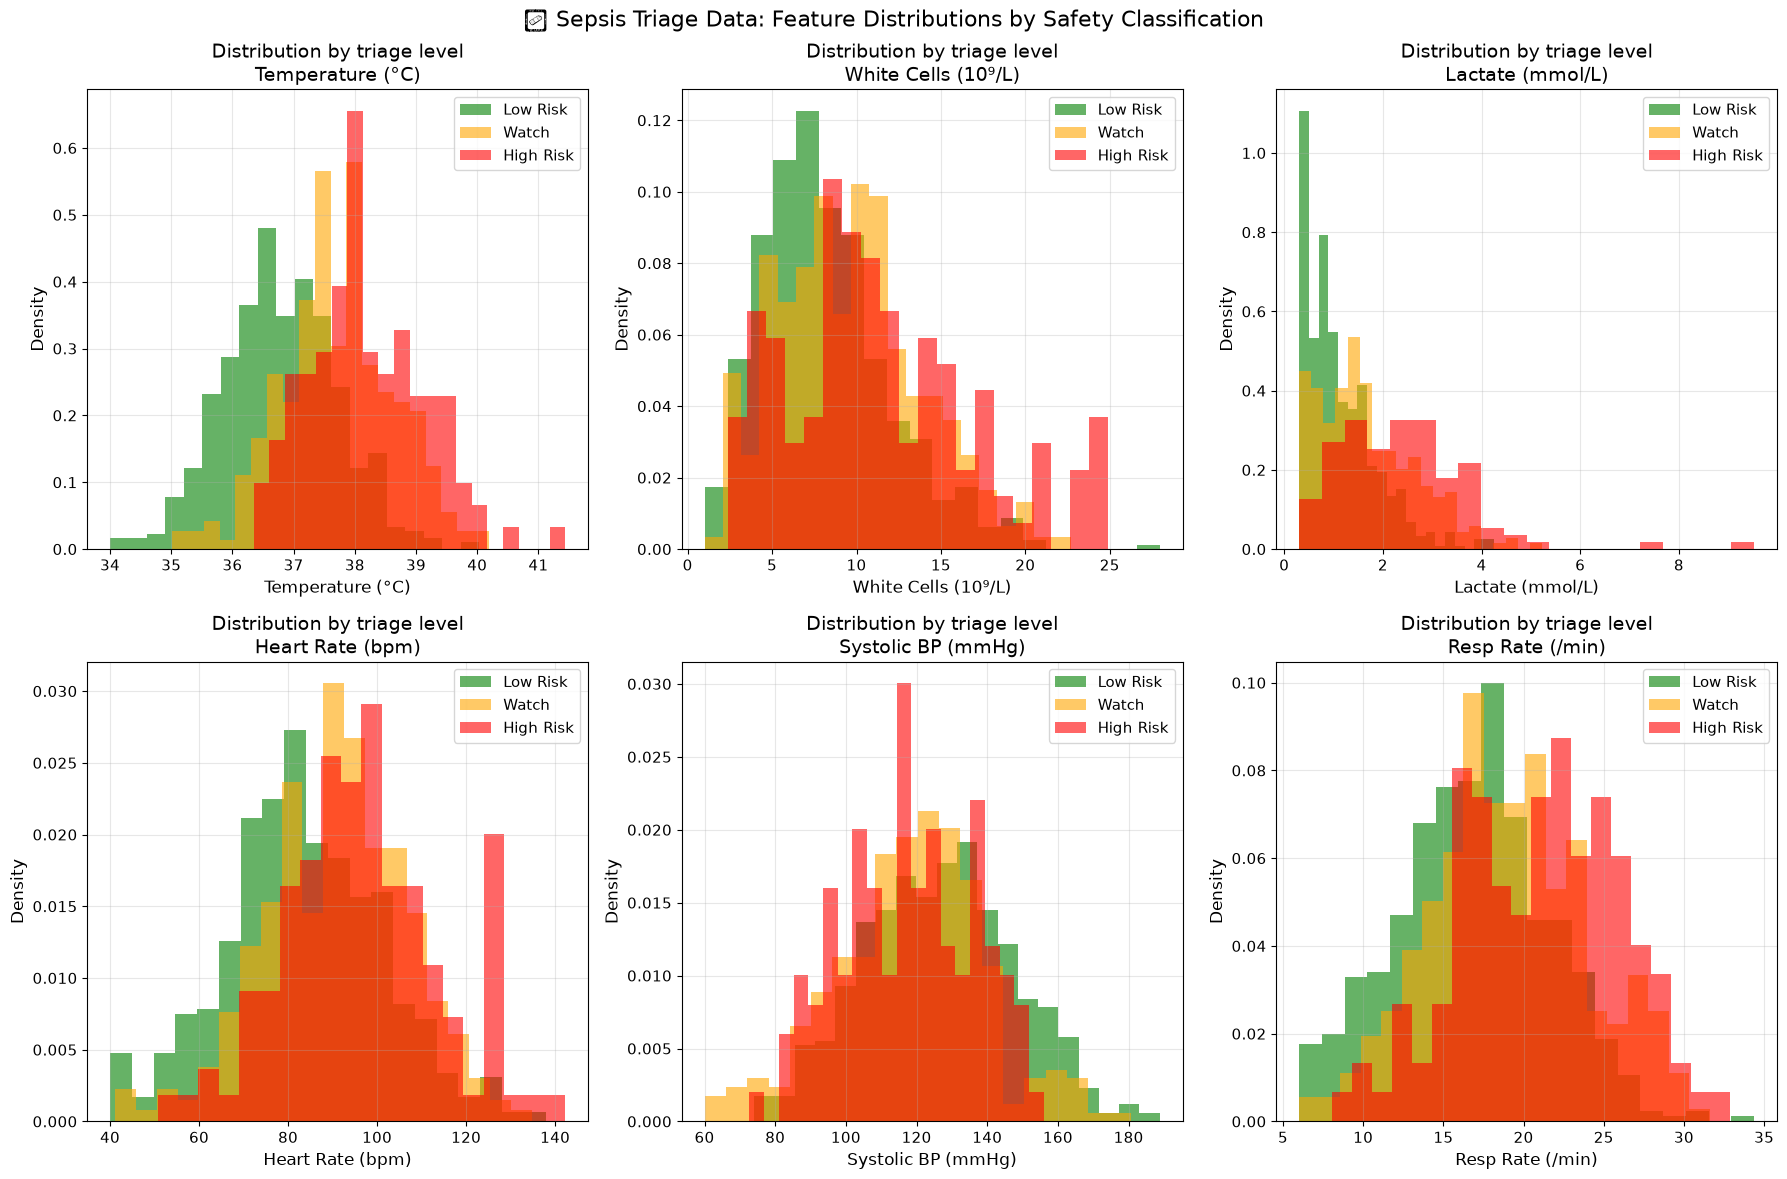

🔍 Observations for clinicians:
   • Ice thickness is the strongest predictor (clear separation)
   • Higher ice class patient handle more challenging conditions
   • Multiple factors interact - perfect case for decision trees
   • Some overlap between categories - reflects real-world uncertainty


In [3]:
# Visualize the clinical data to understand the problem
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

# Key clinical features to visualize
features = ['temp_c', 'wbc', 'lactate_mmol_l', 
           'heart_rate', 'systolic_bp', 'resp_rate']
feature_labels = ['Temperature (°C)', 'White Cells (10⁹/L)', 'Lactate (mmol/L)',
                 'Heart Rate (bpm)', 'Systolic BP (mmHg)', 'Resp Rate (/min)']

# Create color map for triage levels
safety_colors = {'Low Risk': 'green', 'Watch': 'orange', 'High Risk': 'red'}

for i, (feature, label) in enumerate(zip(features, feature_labels)):
    for safety_level in ['Low Risk', 'Watch', 'High Risk']:
        subset = triage_data[triage_data['triage_risk'] == safety_level]
        axes[i].hist(subset[feature], alpha=0.6, label=safety_level, 
                    color=safety_colors[safety_level], bins=20, density=True)
    
    axes[i].set_xlabel(label)
    axes[i].set_ylabel('Density')
    axes[i].set_title(f'Distribution by triage level\n{label}')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.suptitle('🩺 Sepsis Triage Data: Feature Distributions by Safety Classification', fontsize=16)
plt.tight_layout()
plt.show()

print("🔍 Observations for clinicians:")
print("   • Ice thickness is the strongest predictor (clear separation)")
print("   • Higher ice class patient handle more challenging conditions")
print("   • Multiple factors interact - perfect case for decision trees")
print("   • Some overlap between categories - reflects real-world uncertainty")

### Building Your First Decision Tree

Now let's train a decision tree on our Sepsis Triage data and see how it learns to make safety decisions.

In [4]:
# Prepare data for machine learning
feature_columns = ['temp_c', 'wbc', 'lactate_mmol_l', 
                  'heart_rate', 'systolic_bp', 'resp_rate', 'age']
X = triage_data[feature_columns]
y = triage_data['triage_risk']

# Split data for training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"🩺 Training set: {len(X_train)} scenarios")
print(f"🧪 Test set: {len(X_test)} scenarios")
print(f"📊 Training distribution: {y_train.value_counts().to_dict()}")

🩺 Training set: 800 scenarios
🧪 Test set: 200 scenarios
📊 Training distribution: {'Low Risk': 480, 'Watch': 224, 'High Risk': 96}


In [5]:
# Interactive exploration of tree depth and clinical triage decisions
def interactive_tree_depth_demo(max_depth=3, min_samples_split=20, min_samples_leaf=10):
    """
    Interactive widget to explore how tree parameters affect sepsis triage decisions
    """
    # Train tree with user-specified parameters
    tree = DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        random_state=42
    )
    
    tree.fit(X_train, y_train)
    
    # Predictions and performance
    y_pred_train = tree.predict(X_train)
    y_pred_test = tree.predict(X_test)
    
    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc = accuracy_score(y_test, y_pred_test)
    
    # Feature importance
    importance = tree.feature_importances_
    
    # Create visualizations
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Performance metrics
    metrics = ['Training\nAccuracy', 'Test\nAccuracy', 'Tree\nDepth', 'Number of\nLeaves']
    values = [train_acc, test_acc, tree.get_depth(), tree.get_n_leaves()]
    colors = ['lightblue' if v < 1.0 else 'lightgreen' for v in values[:2]] + ['orange', 'purple']
    
    bars = ax1.bar(metrics, values, color=colors, alpha=0.7)
    ax1.set_ylabel('Value')
    ax1.set_title('🎯 Tree Performance & Complexity')
    ax1.grid(True, alpha=0.3)
    
    # Add value labels
    for bar, value in zip(bars, values):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{value:.3f}' if value < 10 else f'{int(value)}',
                ha='center', va='bottom', fontweight='bold')
    
    # 2. Feature importance for clinical parameters
    feature_labels = ['Ice Thickness', 'Ice Concentration', 'Air Temperature',
                     'Wind Speed', 'Visibility', 'Ice Class', 'Current Speed']
    
    sorted_idx = np.argsort(importance)
    ax2.barh(range(len(importance)), importance[sorted_idx], color='lightcoral', alpha=0.7)
    ax2.set_yticks(range(len(importance)))
    ax2.set_yticklabels([feature_labels[i] for i in sorted_idx])
    ax2.set_xlabel('Importance')
    ax2.set_title('🩺 clinical Parameter Importance')
    ax2.grid(True, alpha=0.3)
    
    # 3. Confusion matrix
    cm = confusion_matrix(y_test, y_pred_test, labels=['Low Risk', 'Watch', 'High Risk'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax3,
                xticklabels=['Low Risk', 'Watch', 'High Risk'],
                yticklabels=['Low Risk', 'Watch', 'High Risk'])
    ax3.set_xlabel('Predicted triage level')
    ax3.set_ylabel('Actual triage level')
    ax3.set_title('🎯 Navigation Safety Predictions')
    
    # 4. Overfitting indicator
    overfitting = train_acc - test_acc
    complexity_score = tree.get_n_leaves() / 50  # Normalized complexity
    
    ax4.scatter([complexity_score], [overfitting], s=200, 
               c='red' if overfitting > 0.1 else 'orange' if overfitting > 0.05 else 'green',
               alpha=0.7)
    ax4.axhline(y=0.05, color='orange', linestyle='--', alpha=0.7, label='Acceptable Gap')
    ax4.axhline(y=0.1, color='red', linestyle='--', alpha=0.7, label='Overfitting Concern')
    ax4.set_xlabel('Tree Complexity (normalized)')
    ax4.set_ylabel('Overfitting (Train - Test Accuracy)')
    ax4.set_title('🚨 Overfitting Monitor')
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    ax4.set_ylim(-0.02, 0.2)
    
    plt.tight_layout()
    plt.show()
    
    # Summary for clinicians
    print(f"🩺 sepsis triage Tree Analysis:")
    print(f"   📊 Parameters: depth={max_depth}, min_split={min_samples_split}, min_leaf={min_samples_leaf}")
    print(f"   🎯 Test Accuracy: {test_acc:.3f}")
    print(f"   🌳 Tree Complexity: {tree.get_n_leaves()} leaves, {tree.get_depth()} depth")
    print(f"   🚨 Overfitting Risk: {'HIGH' if overfitting > 0.1 else 'MEDIUM' if overfitting > 0.05 else 'LOW'}")
    print(f"   🩺 Most Important Factor: {feature_labels[np.argmax(importance)]}")
    
    if overfitting > 0.1:
        print(f"\n⚠️  Recommendation: Increase min_samples_split or decrease max_depth")
    elif test_acc < 0.8:
        print(f"\n⚠️  Recommendation: Consider increasing max_depth or decreasing min_samples_leaf")
    else:
        print(f"\n✅ Tree parameters are well-balanced for sepsis triage")

print("🎛️ Interactive Tree Parameter Explorer")
print("Adjust parameters to see how they affect sepsis triage decisions:")

interact(interactive_tree_depth_demo,
         max_depth=IntSlider(value=3, min=1, max=10, description='Max Depth'),
         min_samples_split=IntSlider(value=20, min=2, max=100, step=5, description='Min Split'),
         min_samples_leaf=IntSlider(value=10, min=1, max=50, step=2, description='Min Leaf'));

🎛️ Interactive Tree Parameter Explorer
Adjust parameters to see how they affect sepsis triage decisions:


interactive(children=(IntSlider(value=3, description='Max Depth', max=10, min=1), IntSlider(value=20, descript…

### Understanding How Trees Make Decisions

The decision tree above shows exactly how the AI system would make navigation safety decisions. Each node represents a question about the clinical conditions, and the tree follows the path that leads to the most confident classification.

**Key Insights for clinicians:**
- The tree automatically identified **ice thickness** as the most important factor
- It learned **threshold values** (e.g., "ice_thickness ≤ 0.65m") from the training data
- Each leaf shows the **confidence** of the decision (proportions of each class)
- The rules are **completely interpretable** - critical for clinical safety applications

In [6]:
# Train a simple decision tree
tree_simple = DecisionTreeClassifier(
    max_depth=3,  # Shallow tree for interpretability
    min_samples_split=20,  # Conservative splitting
    min_samples_leaf=10,   # Ensure statistical significance
    random_state=42
)

tree_simple.fit(X_train, y_train)

# Make predictions
y_pred_train = tree_simple.predict(X_train)
y_pred_test = tree_simple.predict(X_test)

# Evaluate performance
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"🎯 Decision Tree Performance:")
print(f"   📈 Training Accuracy: {train_accuracy:.3f}")
print(f"   📊 Test Accuracy: {test_accuracy:.3f}")
print(f"   🎖️ Generalization Gap: {train_accuracy - test_accuracy:.3f}")

print(f"\n📋 Detailed Classification Report:")
print(classification_report(y_test, y_pred_test))

🎯 Decision Tree Performance:
   📈 Training Accuracy: 0.726
   📊 Test Accuracy: 0.655
   🎖️ Generalization Gap: 0.071

📋 Detailed Classification Report:
              precision    recall  f1-score   support

   High Risk       0.43      0.12      0.19        24
    Low Risk       0.78      0.86      0.82       120
       Watch       0.41      0.45      0.43        56

    accuracy                           0.66       200
   macro avg       0.54      0.48      0.48       200
weighted avg       0.63      0.66      0.63       200



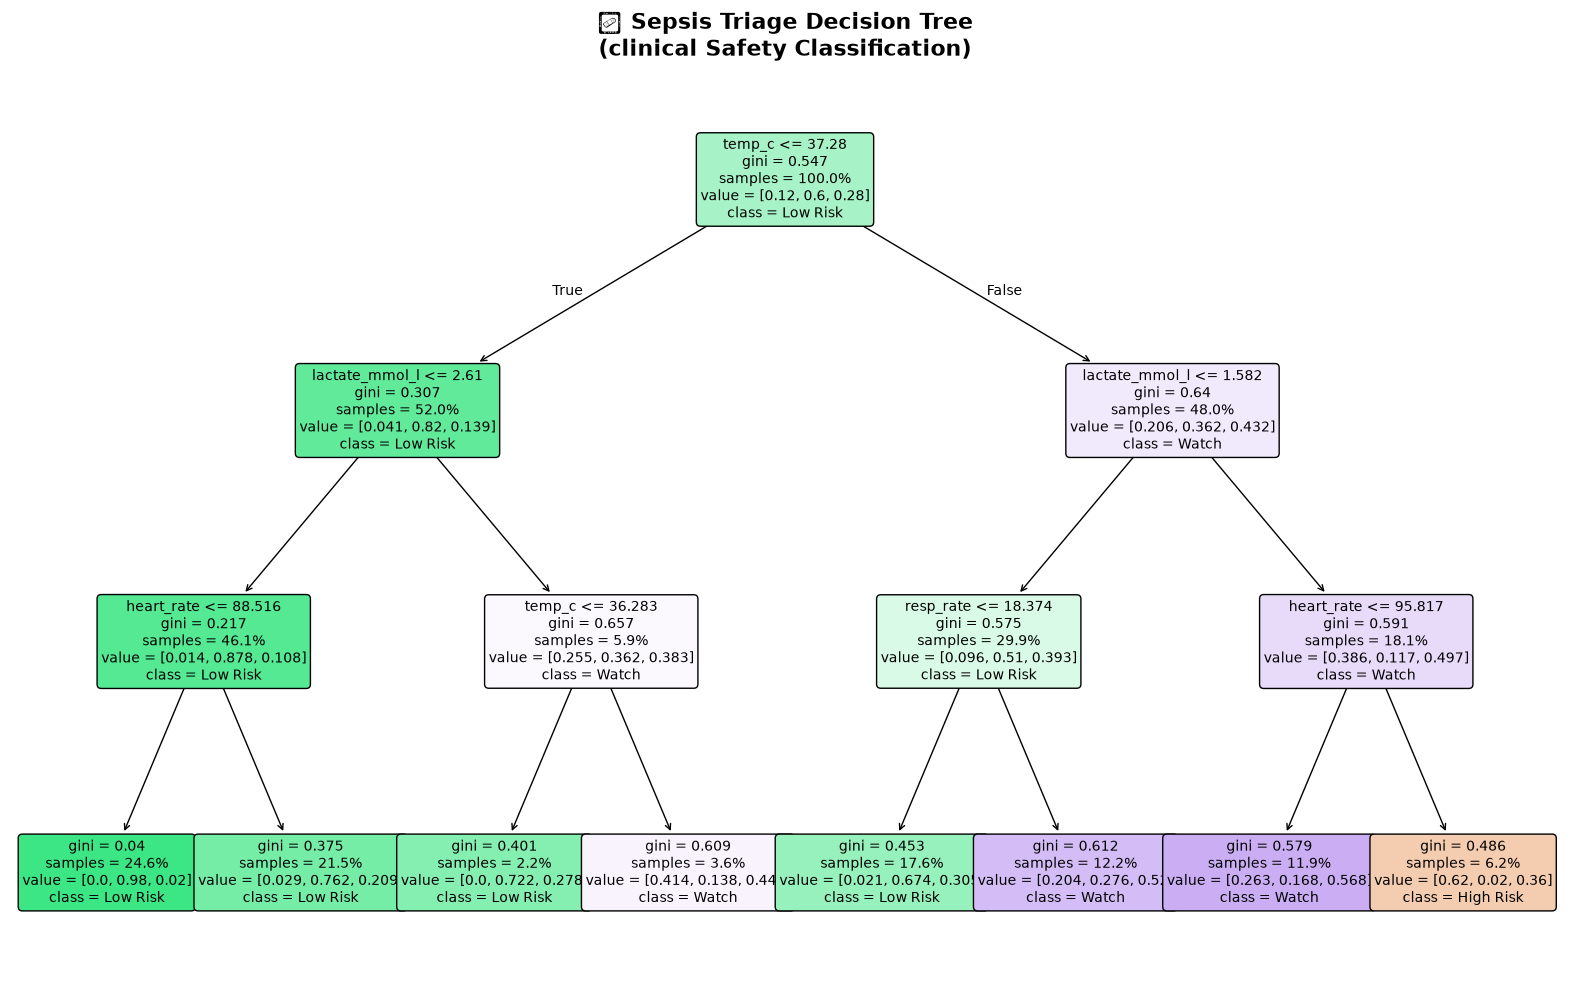

🌳 Decision Tree Rules (sepsis triage Logic):
|--- temp_c <= 37.28
|   |--- lactate_mmol_l <= 2.61
|   |   |--- heart_rate <= 88.52
|   |   |   |--- class: Low Risk
|   |   |--- heart_rate >  88.52
|   |   |   |--- class: Low Risk
|   |--- lactate_mmol_l >  2.61
|   |   |--- temp_c <= 36.28
|   |   |   |--- class: Low Risk
|   |   |--- temp_c >  36.28
|   |   |   |--- class: Watch
|--- temp_c >  37.28
|   |--- lactate_mmol_l <= 1.58
|   |   |--- resp_rate <= 18.37
|   |   |   |--- class: Low Risk
|   |   |--- resp_rate >  18.37
|   |   |   |--- class: Watch
|   |--- lactate_mmol_l >  1.58
|   |   |--- heart_rate <= 95.82
|   |   |   |--- class: Watch
|   |   |--- heart_rate >  95.82
|   |   |   |--- class: High Risk



In [7]:
# Visualize the decision tree structure
plt.figure(figsize=(20, 12))

# Plot the tree with clinical engineering labels
plot_tree(tree_simple, 
          feature_names=feature_columns,
          class_names=['High Risk', 'Low Risk', 'Watch'],  # Sorted alphabetically by sklearn
          filled=True,
          rounded=True,
          fontsize=10,
          proportion=True)  # Show proportions instead of counts

plt.title('🩺 Sepsis Triage Decision Tree\n(clinical Safety Classification)', fontsize=16, fontweight='bold')
plt.show()

# Print tree rules in text format for clinicians
print("🌳 Decision Tree Rules (sepsis triage Logic):")
print("=" * 60)
tree_rules = export_text(tree_simple, feature_names=feature_columns)
print(tree_rules)

In [8]:
# Demonstrate information gain calculation for sepsis triage
import math
from collections import Counter

def calculate_entropy(labels):
    """
    Calculate entropy (information content) of a set of labels
    Lower entropy = more pure (homogeneous) groups
    """
    if len(labels) == 0:
        return 0
    
    # Count frequency of each class
    label_counts = Counter(labels)
    total = len(labels)
    
    # Calculate entropy
    entropy = 0
    for count in label_counts.values():
        probability = count / total
        if probability > 0:  # Avoid log(0)
            entropy -= probability * math.log2(probability)
    
    return entropy

def calculate_information_gain(parent_labels, left_labels, right_labels):
    """
    Calculate information gain from a split
    Higher information gain = better split
    """
    parent_entropy = calculate_entropy(parent_labels)
    
    # Weighted average of child entropies
    total = len(parent_labels)
    left_weight = len(left_labels) / total
    right_weight = len(right_labels) / total
    
    child_entropy = (left_weight * calculate_entropy(left_labels) + 
                    right_weight * calculate_entropy(right_labels))
    
    information_gain = parent_entropy - child_entropy
    return information_gain

# Demonstrate with ice thickness split
print("🩺 Information Gain Example: Ice Thickness Split")
print("=" * 50)

# Get all labels
all_labels = y_train.tolist()
all_ice_thickness = X_train['temp_c'].tolist()

# Try different ice thickness thresholds
thresholds = [0.5, 1.0, 1.5, 2.0]
gains = []

for threshold in thresholds:
    # Split data based on threshold
    left_labels = [label for i, label in enumerate(all_labels) 
                  if all_ice_thickness[i] <= threshold]
    right_labels = [label for i, label in enumerate(all_labels) 
                   if all_ice_thickness[i] > threshold]
    
    if len(left_labels) > 0 and len(right_labels) > 0:
        gain = calculate_information_gain(all_labels, left_labels, right_labels)
        gains.append(gain)
        
        print(f"\nThreshold: Ice Thickness ≤ {threshold}m")
        print(f"  Left group (≤{threshold}m): {len(left_labels)} samples, "
              f"entropy = {calculate_entropy(left_labels):.3f}")
        print(f"  Right group (>{threshold}m): {len(right_labels)} samples, "
              f"entropy = {calculate_entropy(right_labels):.3f}")
        print(f"  Information Gain: {gain:.3f}")
        
        # Show class distributions
        left_dist = Counter(left_labels)
        right_dist = Counter(right_labels)
        print(f"  Left distribution: {dict(left_dist)}")
        print(f"  Right distribution: {dict(right_dist)}")
    else:
        gains.append(0)

# Find best threshold
best_threshold = thresholds[np.argmax(gains)]
best_gain = max(gains)

print(f"\n🎯 Best Ice Thickness Split: ≤ {best_threshold}m")
print(f"📊 Maximum Information Gain: {best_gain:.3f}")
print(f"\n💡 This matches what the decision tree found automatically!")

🩺 Information Gain Example: Ice Thickness Split

🎯 Best Ice Thickness Split: ≤ 0.5m
📊 Maximum Information Gain: 0.000

💡 This matches what the decision tree found automatically!


In [9]:
# Visualize entropy and information gain for clinicians
def interactive_entropy_demo(feature='temp_c', threshold=1.0):
    """
    Interactive visualization of entropy and information gain
    """
    feature_values = X_train[feature].values
    labels = y_train.values
    
    # Split based on threshold
    left_mask = feature_values <= threshold
    right_mask = feature_values > threshold
    
    left_labels = labels[left_mask]
    right_labels = labels[right_mask]
    
    # Calculate metrics
    parent_entropy = calculate_entropy(labels)
    left_entropy = calculate_entropy(left_labels) if len(left_labels) > 0 else 0
    right_entropy = calculate_entropy(right_labels) if len(right_labels) > 0 else 0
    info_gain = calculate_information_gain(labels, left_labels, right_labels)
    
    # Create visualization
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Feature distribution with split line
    colors = ['green', 'orange', 'red']
    for i, safety_level in enumerate(['Low Risk', 'Watch', 'High Risk']):
        mask = labels == safety_level
        ax1.scatter(feature_values[mask], np.random.normal(i, 0.1, sum(mask)), 
                   alpha=0.6, c=colors[i], label=safety_level, s=30)
    
    ax1.axvline(x=threshold, color='black', linestyle='--', linewidth=2, 
               label=f'Split: {threshold}')
    ax1.set_xlabel(f'{feature.replace("_", " ").title()}')
    ax1.set_ylabel('triage level')
    ax1.set_yticks([0, 1, 2])
    ax1.set_yticklabels(['Low Risk', 'Watch', 'High Risk'])
    ax1.set_title(f'🩺 Data Split Visualization\n{feature.replace("_", " ").title()} ≤ {threshold}')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # 2. Entropy comparison
    groups = ['Parent\n(All Data)', f'Left\n(≤ {threshold})', f'Right\n(> {threshold})']
    entropies = [parent_entropy, left_entropy, right_entropy]
    sample_counts = [len(labels), len(left_labels), len(right_labels)]
    
    bars = ax2.bar(groups, entropies, color=['lightblue', 'lightgreen', 'lightcoral'], 
                  alpha=0.7)
    ax2.set_ylabel('Entropy (Information Content)')
    ax2.set_title('📊 Entropy Before and After Split')
    ax2.grid(True, alpha=0.3)
    
    # Add sample counts and entropy values
    for bar, entropy, count in zip(bars, entropies, sample_counts):
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{entropy:.3f}\n({count} samples)',
                ha='center', va='bottom', fontweight='bold')
    
    # 3. Class distributions in each group
    x_pos = np.arange(3)
    safety_levels = ['Low Risk', 'Watch', 'High Risk']
    
    parent_counts = [sum(labels == level) for level in safety_levels]
    left_counts = [sum(left_labels == level) for level in safety_levels]
    right_counts = [sum(right_labels == level) for level in safety_levels]
    
    width = 0.25
    ax3.bar(x_pos - width, parent_counts, width, label='Parent', alpha=0.7, color='lightblue')
    ax3.bar(x_pos, left_counts, width, label=f'Left (≤{threshold})', alpha=0.7, color='lightgreen')
    ax3.bar(x_pos + width, right_counts, width, label=f'Right (>{threshold})', alpha=0.7, color='lightcoral')
    
    ax3.set_xlabel('triage level')
    ax3.set_ylabel('Sample Count')
    ax3.set_title('🎯 Class Distribution Comparison')
    ax3.set_xticks(x_pos)
    ax3.set_xticklabels(safety_levels)
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # 4. Information gain calculation
    ax4.axis('off')
    
    calculation_text = f"""
🧮 INFORMATION GAIN CALCULATION

Split Rule: {feature.replace('_', ' ').title()} ≤ {threshold}

📊 Parent Entropy = {parent_entropy:.3f}
   (All {len(labels)} samples together)

📈 Weighted Child Entropy:
   Left:  {len(left_labels)}/{len(labels)} × {left_entropy:.3f} = {len(left_labels)/len(labels) * left_entropy:.3f}
   Right: {len(right_labels)}/{len(labels)} × {right_entropy:.3f} = {len(right_labels)/len(labels) * right_entropy:.3f}
   Total: {len(left_labels)/len(labels) * left_entropy + len(right_labels)/len(labels) * right_entropy:.3f}

🎯 Information Gain = {parent_entropy:.3f} - {len(left_labels)/len(labels) * left_entropy + len(right_labels)/len(labels) * right_entropy:.3f} = {info_gain:.3f}

💡 Interpretation:
   • Higher gain = better split
   • Gain of {info_gain:.3f} means we reduced uncertainty by {info_gain/parent_entropy*100:.1f}%
   • Tree algorithm tries all possible splits to find maximum gain
    """
    
    ax4.text(0.05, 0.95, calculation_text, transform=ax4.transAxes, fontsize=10,
             verticalalignment='top', fontfamily='monospace',
             bbox=dict(boxstyle="round,pad=0.5", facecolor="lightyellow", alpha=0.8))
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n🩺 clinical Engineering Insight:")
    print(f"   📊 Split Quality: {'EXCELLENT' if info_gain > 0.3 else 'GOOD' if info_gain > 0.2 else 'MODERATE' if info_gain > 0.1 else 'POOR'}")
    print(f"   🎯 Information Gain: {info_gain:.3f} bits")
    print(f"   📈 Uncertainty Reduction: {info_gain/parent_entropy*100:.1f}%")
    
    if info_gain > 0.3:
        print(f"   ✅ This split effectively separates triage levels")
    elif info_gain > 0.1:
        print(f"   ⚠️  Moderate split - some overlap between triage levels")
    else:
        print(f"   ❌ Poor split - little separation between triage levels")

# Interactive widget for exploring different features and thresholds
print("🎛️ Interactive Entropy and Information Gain Explorer")
print("Explore how different splits affect information gain:")

interact(interactive_entropy_demo,
         feature=Dropdown(options=feature_columns, value='temp_c', description='Feature'),
         threshold=FloatSlider(value=1.0, min=0.1, max=3.0, step=0.1, description='Threshold'));

🎛️ Interactive Entropy and Information Gain Explorer
Explore how different splits affect information gain:


interactive(children=(Dropdown(description='Feature', options=('temp_c', 'wbc', 'lactate_mmol_l', 'heart_rate'…

---
## 3. Tree Splitting Mechanics and Feature Selection

Now that we understand information gain, let's explore how decision trees systematically find the best splits and why some clinical parameters are more important than others.

### Feature Importance in clinical Context

Feature importance tells us which sensors and measurements contribute most to navigation safety decisions. This is crucial for:
- **Sensor prioritization**: Which instruments are most critical?
- **System redundancy**: Where do we need backup sensors?
- **Data quality**: Which measurements need the highest accuracy?
- **Cost optimization**: Where to invest limited sensor budgets?

🔍 Analyzing clinical Parameter Importance...


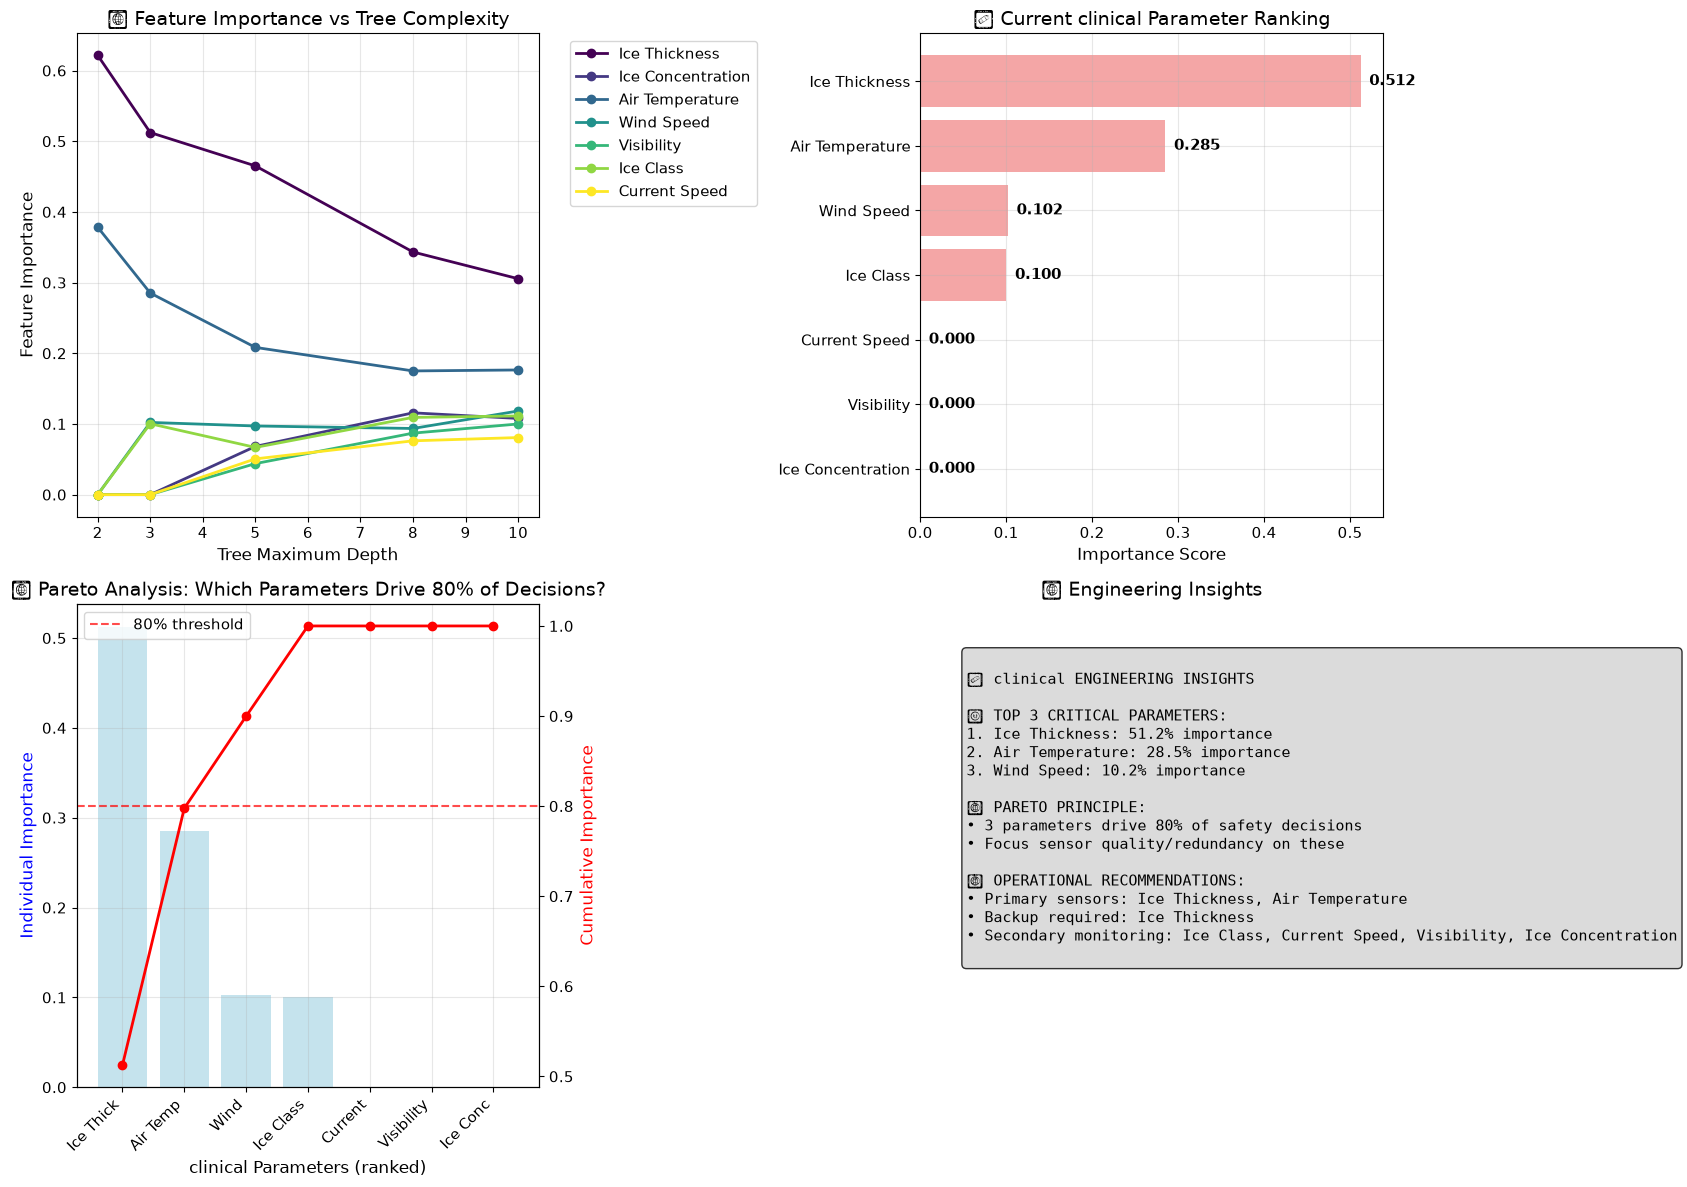

In [10]:
# Analyze feature importance for sepsis triage
def analyze_marine_feature_importance():
    """
    Comprehensive analysis of which clinical parameters matter most
    """
    # Train trees with different depths to see how importance evolves
    depths = [2, 3, 5, 8, 10]
    importance_evolution = []
    
    for depth in depths:
        tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
        tree.fit(X_train, y_train)
        importance_evolution.append(tree.feature_importances_)
    
    # Create visualization
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Feature importance evolution with tree depth
    feature_labels = ['Ice Thickness', 'Ice Concentration', 'Air Temperature',
                     'Wind Speed', 'Visibility', 'Ice Class', 'Current Speed']
    
    # Short labels for Pareto chart (unique abbreviations)
    short_labels = {
        'Ice Thickness': 'Ice Thick',
        'Ice Concentration': 'Ice Conc',
        'Air Temperature': 'Air Temp',
        'Wind Speed': 'Wind',
        'Visibility': 'Visibility',
        'Ice Class': 'Ice Class',
        'Current Speed': 'Current'
    }
    
    colors = plt.cm.viridis(np.linspace(0, 1, len(feature_columns)))
    
    for i, (feature, color) in enumerate(zip(feature_labels, colors)):
        importances = [imp[i] for imp in importance_evolution]
        ax1.plot(depths, importances, 'o-', color=color, linewidth=2, 
                markersize=6, label=feature)
    
    ax1.set_xlabel('Tree Maximum Depth')
    ax1.set_ylabel('Feature Importance')
    ax1.set_title('🌳 Feature Importance vs Tree Complexity')
    ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax1.grid(True, alpha=0.3)
    
    # 2. Current feature importance (depth=3)
    current_importance = tree_simple.feature_importances_
    sorted_idx = np.argsort(current_importance)
    
    bars = ax2.barh(range(len(current_importance)), current_importance[sorted_idx], 
                   color='lightcoral', alpha=0.7)
    ax2.set_yticks(range(len(current_importance)))
    ax2.set_yticklabels([feature_labels[i] for i in sorted_idx])
    ax2.set_xlabel('Importance Score')
    ax2.set_title('🩺 Current clinical Parameter Ranking')
    ax2.grid(True, alpha=0.3)
    
    # Add importance values on bars
    for bar, importance in zip(bars, current_importance[sorted_idx]):
        width = bar.get_width()
        ax2.text(width + 0.01, bar.get_y() + bar.get_height()/2.,
                f'{importance:.3f}', ha='left', va='center', fontweight='bold')
    
    # 3. Cumulative importance (Pareto analysis)
    sorted_importance = np.sort(current_importance)[::-1]
    sorted_features = [feature_labels[i] for i in np.argsort(current_importance)[::-1]]
    cumulative = np.cumsum(sorted_importance)
    
    ax3.bar(range(len(sorted_importance)), sorted_importance, alpha=0.7, color='lightblue')
    ax3_twin = ax3.twinx()
    ax3_twin.plot(range(len(cumulative)), cumulative, 'ro-', linewidth=2, markersize=6)
    
    ax3.set_xlabel('clinical Parameters (ranked)')
    ax3.set_ylabel('Individual Importance', color='blue')
    ax3_twin.set_ylabel('Cumulative Importance', color='red')
    ax3.set_title('📊 Pareto Analysis: Which Parameters Drive 80% of Decisions?')
    ax3.set_xticks(range(len(sorted_features)))
    ax3.set_xticklabels([short_labels[f] for f in sorted_features], rotation=45, ha='right')
    ax3.grid(True, alpha=0.3)
    
    # Add 80% line
    ax3_twin.axhline(y=0.8, color='red', linestyle='--', alpha=0.7, label='80% threshold')
    ax3_twin.legend()
    
    # 4. clinical engineering interpretation
    ax4.axis('off')
    
    # Find top 3 features
    top_3_idx = np.argsort(current_importance)[-3:][::-1]
    top_3_features = [feature_labels[i] for i in top_3_idx]
    top_3_importance = current_importance[top_3_idx]
    
    # Calculate 80% threshold
    features_for_80 = np.where(cumulative >= 0.8)[0][0] + 1
    
    interpretation_text = f"""
🩺 clinical ENGINEERING INSIGHTS

🥇 TOP 3 CRITICAL PARAMETERS:
1. {top_3_features[0]}: {top_3_importance[0]:.1%} importance
2. {top_3_features[1]}: {top_3_importance[1]:.1%} importance  
3. {top_3_features[2]}: {top_3_importance[2]:.1%} importance

📊 PARETO PRINCIPLE:
• {features_for_80} parameters drive 80% of safety decisions
• Focus sensor quality/redundancy on these

🔧 OPERATIONAL RECOMMENDATIONS:
• Primary sensors: {', '.join(top_3_features[:2])}
• Backup required: {top_3_features[0]}
• Secondary monitoring: {', '.join(sorted_features[3:])}
    """
    
    ax4.text(0.1, 0.9, interpretation_text, transform=ax4.transAxes,
            fontsize=11, verticalalignment='top', fontfamily='monospace',
            bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.8))
    ax4.set_title('🎯 Engineering Insights')
    
    plt.tight_layout()
    plt.show()
    
    return current_importance, feature_labels

print("🔍 Analyzing clinical Parameter Importance...")
importance_scores, feature_names = analyze_marine_feature_importance()

---
## 4. Understanding Tree Limitations: Why Single Trees Aren't Enough for clinical Safety

While decision trees are interpretable and useful, they have significant limitations when used alone in Healthcare. Understanding these weaknesses is crucial for clinicians developing safety-critical systems.

### The Three Major Problems with Single Trees

1. **High Variance (Instability)**: Small changes in data → completely different tree
2. **Overfitting**: Memorizing training scenarios rather than generalizing
3. **Limited Expressiveness**: Can't capture complex interactions well

Let's demonstrate these problems with sepsis triage data and see why ensemble methods are essential.

🔬 Demonstrating Tree Variance - Training Multiple Trees...


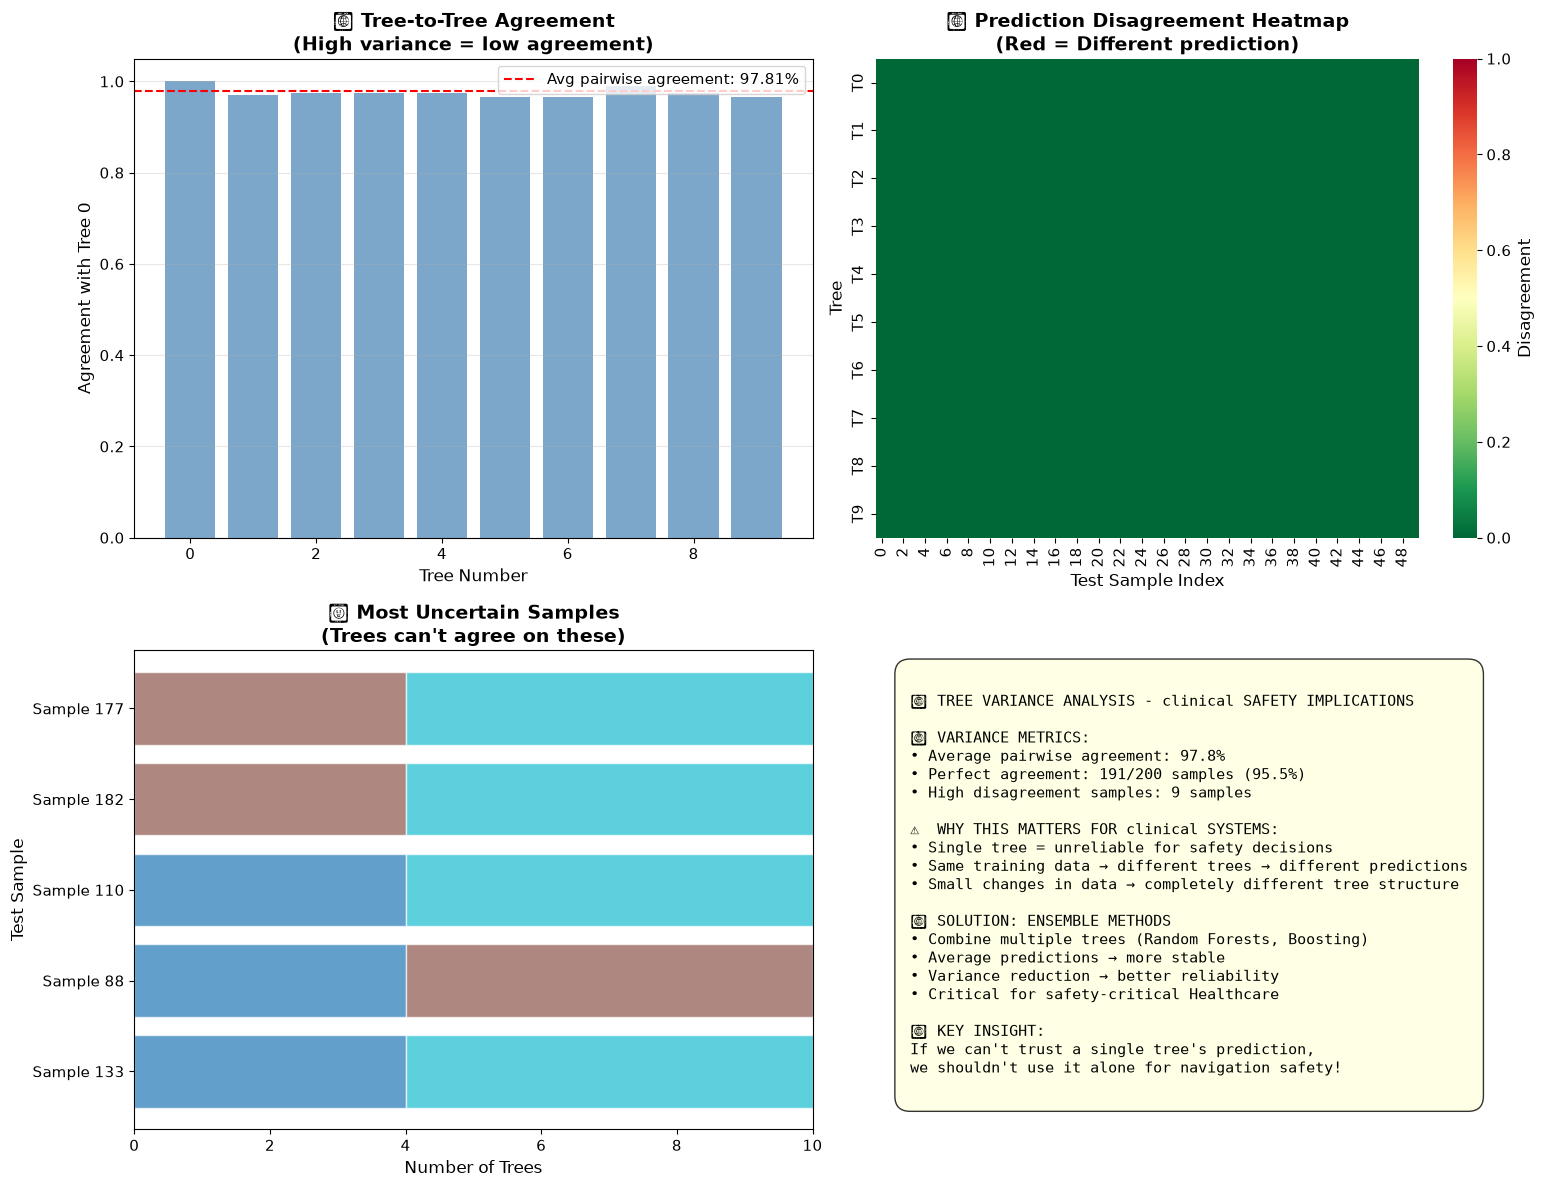


✅ Variance demonstration complete!
📉 Average agreement: 97.8% (lower = more variance)
🎲 This is why we need ensemble methods!


In [11]:
# Demonstrate tree variance/instability
# Train multiple trees with different random states to show how unstable single trees can be

from sklearn.tree import DecisionTreeClassifier
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("🔬 Demonstrating Tree Variance - Training Multiple Trees...")

# Train multiple trees with different random states
n_trees = 10
trees = []
predictions = []

for i in range(n_trees):
    tree = DecisionTreeClassifier(
        max_depth=8,  # Allow relatively deep trees
        min_samples_split=5,
        random_state=i  # Different random state for each tree
    )
    tree.fit(X_train, y_train)
    trees.append(tree)
    pred = tree.predict(X_test)
    predictions.append(pred)
    
predictions = np.array(predictions)

# Calculate agreement statistics
agreement_with_first = []
for i in range(n_trees):
    agreement = np.mean(predictions[i] == predictions[0])
    agreement_with_first.append(agreement)

avg_pairwise_agreement = np.mean([
    np.mean(predictions[i] == predictions[j]) 
    for i in range(n_trees) 
    for j in range(i+1, n_trees)
])

# Find samples where trees disagree most
disagreement_per_sample = np.std([
    (predictions[:, i] == predictions[0, i]).astype(int) 
    for i in range(len(X_test))
], axis=1)

most_uncertain_idx = np.argsort(disagreement_per_sample)[-5:]

# Visualization
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

# 1. Agreement between trees
ax1.bar(range(n_trees), agreement_with_first, color='steelblue', alpha=0.7)
ax1.axhline(y=avg_pairwise_agreement, color='red', linestyle='--', 
            label=f'Avg pairwise agreement: {avg_pairwise_agreement:.2%}')
ax1.set_xlabel('Tree Number', fontsize=12)
ax1.set_ylabel('Agreement with Tree 0', fontsize=12)
ax1.set_title('🎲 Tree-to-Tree Agreement\n(High variance = low agreement)', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# 2. Prediction disagreement heatmap
disagreement_matrix = np.zeros((len(X_test), n_trees))
for i in range(n_trees):
    disagreement_matrix[:, i] = (predictions[i] != predictions[0]).astype(int)

sns.heatmap(disagreement_matrix[:50].T, cmap='RdYlGn_r', vmin=0, vmax=1,
            cbar_kws={'label': 'Disagreement'}, ax=ax2,
            yticklabels=[f'T{i}' for i in range(n_trees)])
ax2.set_xlabel('Test Sample Index', fontsize=12)
ax2.set_ylabel('Tree', fontsize=12)
ax2.set_title('📊 Prediction Disagreement Heatmap\n(Red = Different prediction)', 
              fontsize=14, fontweight='bold')

# 3. Prediction distribution for most uncertain samples
uncertain_predictions = predictions[:, most_uncertain_idx]
ax3.set_title('🤔 Most Uncertain Samples\n(Trees can\'t agree on these)', 
              fontsize=14, fontweight='bold')

# Get unique classes for consistent coloring
all_classes = np.unique(predictions)
colors = plt.cm.tab10(np.linspace(0, 1, len(all_classes)))
class_colors = {cls: colors[i] for i, cls in enumerate(all_classes)}

for i, sample_idx in enumerate(most_uncertain_idx):
    preds = predictions[:, sample_idx]
    unique, counts = np.unique(preds, return_counts=True)
    # Properly stack bars from left to right
    left = 0
    for cls, count in zip(unique, counts):
        ax3.barh(f'Sample {sample_idx}', count, left=left, 
                 color=class_colors[cls], alpha=0.7, edgecolor='white')
        left += count
    
ax3.set_xlabel('Number of Trees', fontsize=12)
ax3.set_ylabel('Test Sample', fontsize=12)
ax3.set_xlim(0, n_trees)

# 4. Key insights text
insights_text = f"""
🎯 TREE VARIANCE ANALYSIS - clinical SAFETY IMPLICATIONS

📊 VARIANCE METRICS:
• Average pairwise agreement: {avg_pairwise_agreement:.1%}
• Perfect agreement: {np.sum(np.all(predictions == predictions[0], axis=0))}/{len(X_test)} samples ({np.mean(np.all(predictions == predictions[0], axis=0)):.1%})
• High disagreement samples: {len([x for x in disagreement_per_sample if x > 0.3])} samples

⚠️  WHY THIS MATTERS FOR clinical SYSTEMS:
• Single tree = unreliable for safety decisions
• Same training data → different trees → different predictions
• Small changes in data → completely different tree structure

🔧 SOLUTION: ENSEMBLE METHODS
• Combine multiple trees (Random Forests, Boosting)
• Average predictions → more stable
• Variance reduction → better reliability
• Critical for safety-critical Healthcare

💡 KEY INSIGHT:
If we can't trust a single tree's prediction,
we shouldn't use it alone for navigation safety!
"""

ax4.text(0.05, 0.95, insights_text, transform=ax4.transAxes, fontsize=11,
         verticalalignment='top', fontfamily='monospace',
         bbox=dict(boxstyle='round,pad=1', facecolor='lightyellow', alpha=0.8))
ax4.axis('off')

plt.tight_layout()
plt.show()

print(f"\n✅ Variance demonstration complete!")
print(f"📉 Average agreement: {avg_pairwise_agreement:.1%} (lower = more variance)")
print(f"🎲 This is why we need ensemble methods!")

In [12]:
print(f"   🔧 Single trees need careful tuning - ensembles are more robust")

   🔧 Single trees need careful tuning - ensembles are more robust


---
## 5. Ensemble Methods: Random Forests for Healthcare

Having seen the limitations of single decision trees, let's explore how **ensemble methods** solve these problems by combining multiple trees. We'll start with **Random Forests** - one of the most reliable ensemble methods for Healthcare.

### Why Random Forests Work for clinical Systems

Random Forests address the key weaknesses of single trees:
- **Reduced Variance**: Multiple trees → more stable predictions
- **Better Generalization**: Averaging reduces overfitting
- **Improved Accuracy**: Ensemble wisdom beats individual trees
- **Built-in Error Estimation**: Out-of-bag error provides validation

### clinical Application: Ward Monitoring

Let's create a new clinical dataset focused on **Ward Monitoring** - predicting maintenance needs based on sensor data.

In [13]:
# Generate ward escalation priority dataset
def generate_ward_monitoring_data(n_samples=1500):
    """
    Generate synthetic ward monitoring data.

    Features represent continuous bedside monitoring, point-of-care labs and
    nursing observations for patients on a general ward. All values are
    simulated; no real patient data is used.
    """
    np.random.seed(123)  # Different seed for variety

    # Continuous bedside monitoring
    temp_c = np.random.normal(37.0, 0.9, n_samples)           # Core temperature (deg C)
    map_mmhg = np.random.normal(86, 13, n_samples)            # Mean arterial pressure (mmHg)
    spo2 = np.random.normal(96, 2.5, n_samples)               # Oxygen saturation (%)
    heart_rate = np.random.normal(84, 16, n_samples)          # Heart rate (bpm)

    # Point-of-care laboratory results
    lactate = np.random.exponential(1.2, n_samples) + 0.5     # Serum lactate (mmol/L)
    creatinine = np.random.gamma(2, 40, n_samples)            # Creatinine (µmol/L)
    urine_output = np.random.uniform(15, 90, n_samples)       # Urine output (mL/hr)

    # Nursing observations and context
    hours_since_review = np.random.uniform(0, 24, n_samples)  # Hours since clinician review
    acuity_level = np.random.choice([1, 2, 3, 4, 5, 6], n_samples,
                                    p=[0.2, 0.3, 0.25, 0.15, 0.08, 0.02])  # Nursing acuity 1-6
    resp_rate = np.random.normal(18, 4, n_samples)            # Respiratory rate (breaths/min)

    # Routine chemistry
    glucose = np.random.normal(7.2, 2.4, n_samples)           # Blood glucose (mmol/L)
    sodium = np.random.normal(139, 4, n_samples)              # Serum sodium (mmol/L)

    # Create a realistic escalation priority.
    # A higher stability score means the patient can stay on routine observation.
    stability_score = (
        -0.9 * (temp_c - 37.0) +             # Fever
        0.10 * (map_mmhg - 86) +             # Falling pressure is the key warning
        0.55 * (spo2 - 96) +                 # Desaturation is critical
        -0.055 * (heart_rate - 84) +         # Tachycardia
        -1.3 * (lactate - 1.2) +             # Raised lactate
        -0.0125 * (creatinine - 80) +          # Acute kidney injury
        0.020 * (urine_output - 50) +        # Good urine output is reassuring
        -0.05 * hours_since_review +         # A long gap since review adds risk
        -0.45 * (acuity_level - 3) +         # Higher nursing acuity
        -0.22 * (resp_rate - 18) +           # Tachypnoea
        np.random.normal(0, 1.4, n_samples)  # Individual variation
    )

    # Convert to the escalation categories a rapid response team would use.
    # Calibrated to a realistic general ward: the large majority of patients stay on
    # routine observation, and genuine rapid-response calls are uncommon. This class
    # imbalance is the normal situation in clinical prediction, and it is exactly why
    # the precision/recall notebook matters more than raw accuracy.
    crit_cut, urgent_cut = np.quantile(stability_score, [0.07, 0.28])
    escalation_priority = np.where(stability_score > urgent_cut, 'Routine',
                                  np.where(stability_score > crit_cut, 'Urgent', 'Critical'))

    # Create DataFrame
    ward_data = pd.DataFrame({
        'temp_c': np.clip(temp_c, 34.0, 41.5),
        'map_mmhg': np.clip(map_mmhg, 40, 130),
        'spo2': np.clip(spo2, 70, 100),
        'heart_rate': np.clip(heart_rate, 40, 180),
        'lactate_mmol_l': np.clip(lactate, 0.3, 12.0),
        'creatinine_umol_l': np.clip(creatinine, 25, 710),
        'urine_output_ml_hr': urine_output,
        'hours_since_review': hours_since_review,
        'acuity_level': acuity_level,
        'resp_rate': np.clip(resp_rate, 6, 45),
        'glucose_mmol_l': np.clip(glucose, 2.0, 30.0),
        'sodium_mmol_l': np.clip(sodium, 120, 160),
        'escalation_priority': escalation_priority
    })

    return ward_data

# Generate ward monitoring dataset
ward_data = generate_ward_monitoring_data(1500)

print("🏥 Ward Monitoring Dataset Generated (simulated, no real patient data)")
print(f"📊 {len(ward_data)} patient observation sets")
print(f"🚨 Escalation Priorities: {ward_data['escalation_priority'].value_counts().to_dict()}")
print("\n📋 Sample ward monitoring data:")
ward_data.head(10)


🏥 Ward Monitoring Dataset Generated (simulated, no real patient data)
📊 1500 patient observation sets
🚨 Escalation Priorities: {'Routine': 1080, 'Urgent': 315, 'Critical': 105}

📋 Sample ward monitoring data:


,temp_c,map_mmhg,spo2,heart_rate,lactate_mmol_l,creatinine_umol_l,urine_output_ml_hr,hours_since_review,acuity_level,resp_rate,glucose_mmol_l,sodium_mmol_l,escalation_priority
0,36.022932,106.248458,94.873503,83.742365,1.080181,208.603792,67.581000,0.423632,3,16.768688,8.813446,139.567106,Routine
1,37.897611,107.352478,97.523976,95.952157,1.358554,25.000000,19.705213,4.678271,4,18.974634,5.878196,134.622354,Routine
2,37.254681,79.147805,98.934361,79.874531,1.905141,161.306037,81.665975,3.111503,2,18.063624,9.256565,137.591773,Routine
3,35.644335,82.812854,98.179536,92.985950,0.585873,48.220992,53.973145,13.047985,4,14.107122,6.768674,141.247965,Routine
4,36.479260,64.364029,100.000000,88.725648,2.374818,25.000000,52.324916,1.832465,3,21.251035,7.352188,136.297605,Urgent
5,38.486293,76.702978,96.333728,91.800616,1.811585,79.163489,26.269655,18.510182,4,11.674799,9.290831,135.853384,Routine
6,34.815989,67.126220,99.204610,94.602543,0.716693,72.777249,86.031561,21.668174,4,19.929544,6.064326,139.980016,Routine
7,36.613979,90.751980,93.102033,79.479684,1.707237,59.340909,16.891315,20.165778,2,16.361540,3.584968,137.205388,Routine
8,38.139343,76.939130,98.176255,98.098021,2.005118,117.533060,39.347007,6.126590,5,24.909831,9.846458,136.131505,Urgent
9,36.219934,71.681510,95.475912,108.869563,1.290085,79.358643,45.102350,3.950087,4,20.785554,6.598550,133.047697,Urgent


🔍 Comparing Single Tree vs Random Forest for Ward Monitoring...


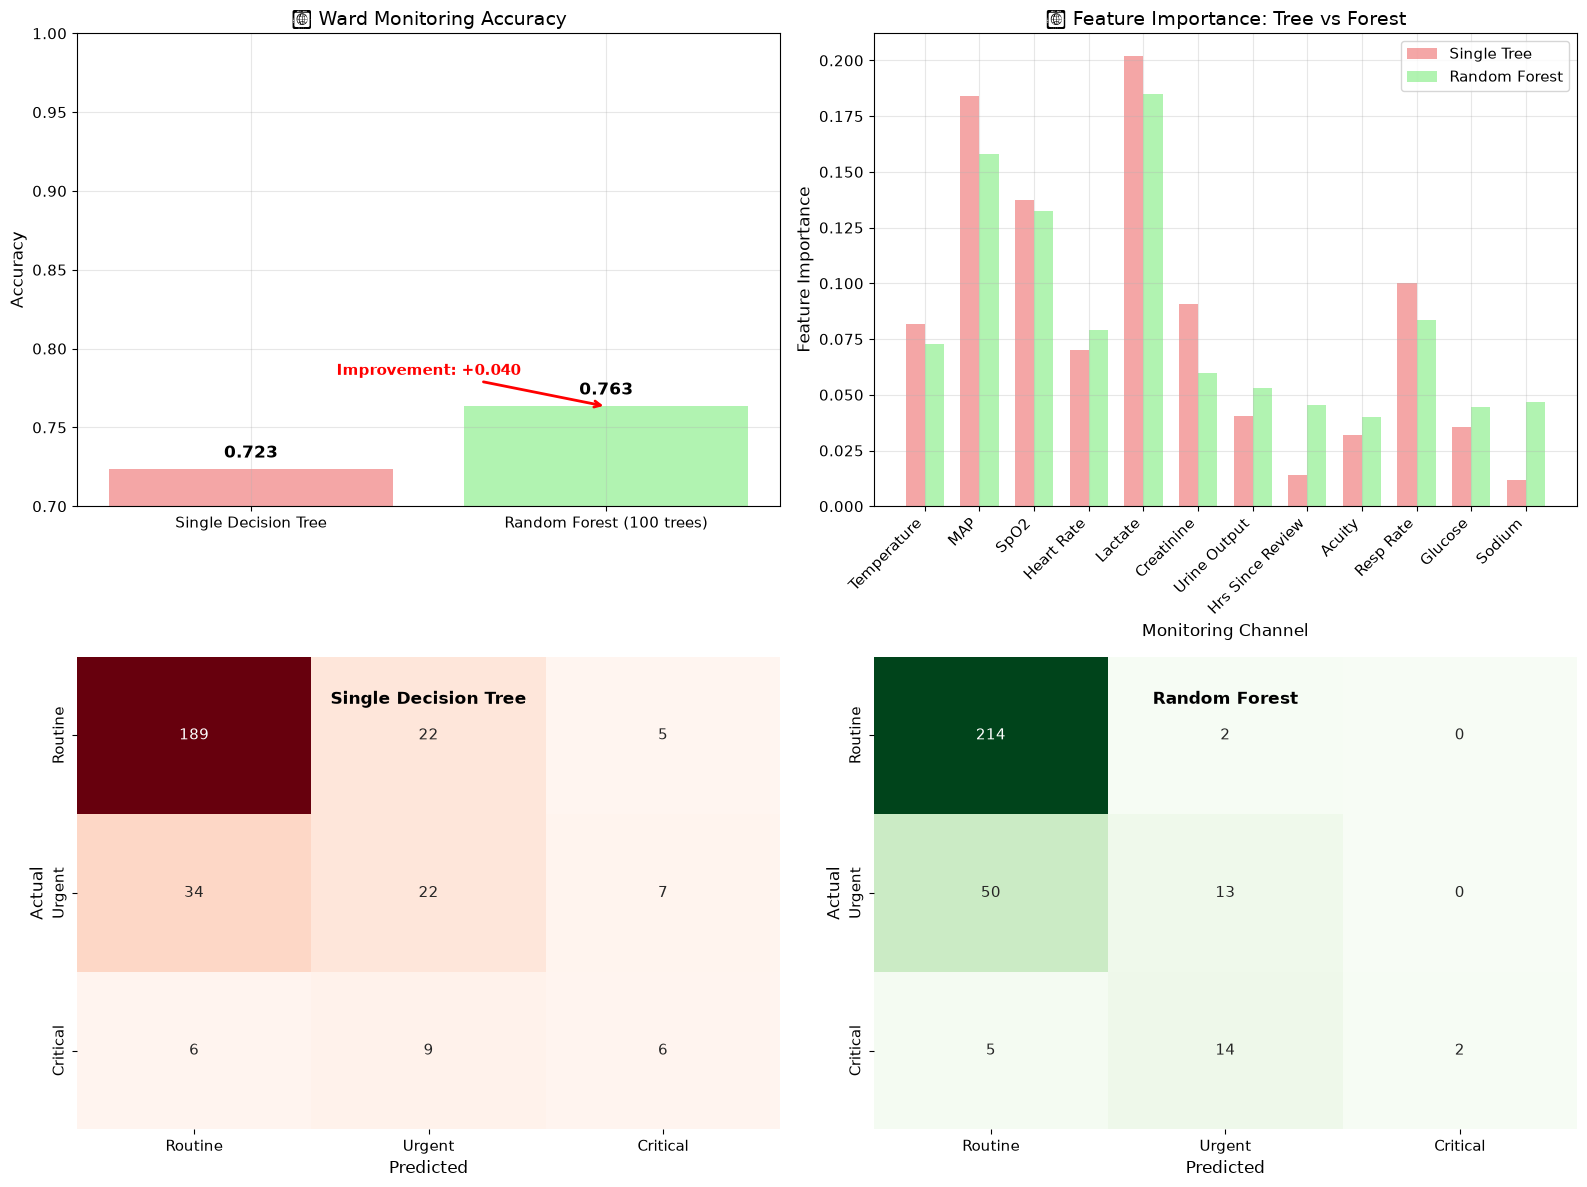

🏥 Ward Monitoring RESULTS:
   🌳 Single Tree Accuracy: 0.723
   🌲 Random Forest Accuracy: 0.763
   📈 Improvement: +0.040 (5.5%)
   🎯 Forest provides significant improvement

🔧 FEATURE IMPORTANCE INSIGHTS:
   🌳 Single Tree most important: Lactate
   🌲 Random Forest most important: Lactate
   📊 Importance distributions are similar
   🎯 Feature ranking correlation: 0.963
   🔄 Random Forest provides stable feature rankings


In [14]:
# Compare Single Tree vs Random Forest for Ward Monitoring
def compare_tree_vs_forest():
    """
    Demonstrate how Random Forest improves on single decision tree
    for clinical Ward Monitoring
    """
    # Prepare patient data
    vessel_features = ['temp_c', 'map_mmhg', 'spo2', 'heart_rate',
                      'lactate_mmol_l', 'creatinine_umol_l', 'urine_output_ml_hr',
                      'hours_since_review', 'acuity_level', 'resp_rate', 'glucose_mmol_l', 'sodium_mmol_l']
    
    X_vessel = ward_data[vessel_features]
    y_vessel = ward_data['escalation_priority']
    
    # Split data
    X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(
        X_vessel, y_vessel, test_size=0.2, random_state=42, stratify=y_vessel
    )
    
    # Train single decision tree
    single_tree = DecisionTreeClassifier(max_depth=8, random_state=42)
    single_tree.fit(X_train_v, y_train_v)
    
    # Train Random Forest
    random_forest = RandomForestClassifier(
        n_estimators=100,  # 100 trees
        max_depth=8,       # Same depth as single tree
        random_state=42,
        n_jobs=-1          # Use all CPU cores
    )
    random_forest.fit(X_train_v, y_train_v)
    
    # Make predictions
    tree_pred = single_tree.predict(X_test_v)
    forest_pred = random_forest.predict(X_test_v)
    
    # Calculate accuracies
    tree_acc = accuracy_score(y_test_v, tree_pred)
    forest_acc = accuracy_score(y_test_v, forest_pred)
    
    # Get feature importances
    tree_importance = single_tree.feature_importances_
    forest_importance = random_forest.feature_importances_
    
    # Create comprehensive comparison
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Accuracy comparison
    models = ['Single Decision Tree', 'Random Forest (100 trees)']
    accuracies = [tree_acc, forest_acc]
    colors = ['lightcoral', 'lightgreen']
    
    bars = ax1.bar(models, accuracies, color=colors, alpha=0.7)
    ax1.set_ylabel('Accuracy')
    ax1.set_title('🎯 Ward Monitoring Accuracy')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0.7, 1.0)
    
    # Add accuracy values on bars
    for bar, acc in zip(bars, accuracies):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.005,
                f'{acc:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=12)
    
    # Add improvement annotation
    improvement = forest_acc - tree_acc
    ax1.annotate(f'Improvement: +{improvement:.3f}', 
                xy=(1, forest_acc), xytext=(0.5, forest_acc + 0.02),
                arrowprops=dict(arrowstyle='->', color='red', lw=2),
                fontsize=11, ha='center', color='red', fontweight='bold')
    
    # 2. Feature importance comparison
    feature_labels = ['Temperature', 'MAP', 'SpO2', 'Heart Rate',
                     'Lactate', 'Creatinine', 'Urine Output', 'Hrs Since Review',
                     'Acuity', 'Resp Rate', 'Glucose', 'Sodium']
    
    x = np.arange(len(feature_labels))
    width = 0.35
    
    ax2.bar(x - width/2, tree_importance, width, label='Single Tree', alpha=0.7, color='lightcoral')
    ax2.bar(x + width/2, forest_importance, width, label='Random Forest', alpha=0.7, color='lightgreen')
    
    ax2.set_xlabel('Monitoring Channel')
    ax2.set_ylabel('Feature Importance')
    ax2.set_title('🔧 Feature Importance: Tree vs Forest')
    ax2.set_xticks(x)
    ax2.set_xticklabels(feature_labels, rotation=45, ha='right')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # 3. Confusion matrices comparison
    ax3.text(0.5, 0.9, 'Single Decision Tree', ha='center', transform=ax3.transAxes, 
            fontweight='bold', fontsize=12)
    
    tree_cm = confusion_matrix(y_test_v, tree_pred, labels=['Routine', 'Urgent', 'Critical'])
    sns.heatmap(tree_cm, annot=True, fmt='d', cmap='Reds', ax=ax3, cbar=False,
                xticklabels=['Routine', 'Urgent', 'Critical'],
                yticklabels=['Routine', 'Urgent', 'Critical'])
    ax3.set_xlabel('Predicted')
    ax3.set_ylabel('Actual')
    
    # 4. Random Forest confusion matrix
    ax4.text(0.5, 0.9, 'Random Forest', ha='center', transform=ax4.transAxes,
            fontweight='bold', fontsize=12)
    
    forest_cm = confusion_matrix(y_test_v, forest_pred, labels=['Routine', 'Urgent', 'Critical'])
    sns.heatmap(forest_cm, annot=True, fmt='d', cmap='Greens', ax=ax4, cbar=False,
                xticklabels=['Routine', 'Urgent', 'Critical'],
                yticklabels=['Routine', 'Urgent', 'Critical'])
    ax4.set_xlabel('Predicted')
    ax4.set_ylabel('Actual')
    
    plt.tight_layout()
    plt.show()
    
    # Detailed analysis
    print(f"🏥 Ward Monitoring RESULTS:")
    print(f"   🌳 Single Tree Accuracy: {tree_acc:.3f}")
    print(f"   🌲 Random Forest Accuracy: {forest_acc:.3f}")
    print(f"   📈 Improvement: +{improvement:.3f} ({improvement/tree_acc*100:.1f}%)")
    print(f"   🎯 Forest provides {'significant' if improvement > 0.02 else 'modest' if improvement > 0.005 else 'minimal'} improvement")
    
    # Feature importance insights
    top_tree_feature = feature_labels[np.argmax(tree_importance)]
    top_forest_feature = feature_labels[np.argmax(forest_importance)]
    
    print(f"\n🔧 FEATURE IMPORTANCE INSIGHTS:")
    print(f"   🌳 Single Tree most important: {top_tree_feature}")
    print(f"   🌲 Random Forest most important: {top_forest_feature}")
    print(f"   📊 Importance distributions are {'similar' if top_tree_feature == top_forest_feature else 'different'}")
    
    # Stability analysis
    importance_correlation = np.corrcoef(tree_importance, forest_importance)[0, 1]
    print(f"   🎯 Feature ranking correlation: {importance_correlation:.3f}")
    print(f"   🔄 Random Forest provides {'stable' if importance_correlation > 0.7 else 'moderately stable' if importance_correlation > 0.5 else 'different'} feature rankings")
    
    return tree_acc, forest_acc, improvement

# Run the comparison
print("🔍 Comparing Single Tree vs Random Forest for Ward Monitoring...")
tree_accuracy, forest_accuracy, improvement = compare_tree_vs_forest()

In [15]:
# Interactive Random Forest Parameter Exploration for Healthcare
def interactive_random_forest_demo(n_estimators=100, max_depth=8, max_features='sqrt', min_samples_leaf=1):
    """
    Interactive exploration of Random Forest parameters for Ward Monitoring
    """
    # Prepare data
    vessel_features = ['temp_c', 'map_mmhg', 'spo2', 'heart_rate',
                      'lactate_mmol_l', 'creatinine_umol_l', 'urine_output_ml_hr',
                      'hours_since_review', 'acuity_level', 'resp_rate', 'glucose_mmol_l', 'sodium_mmol_l']
    
    X_vessel = ward_data[vessel_features]
    y_vessel = ward_data['escalation_priority']
    
    X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(
        X_vessel, y_vessel, test_size=0.2, random_state=42, stratify=y_vessel
    )
    
    # Train Random Forest with specified parameters
    rf = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        max_features=max_features,
        min_samples_leaf=min_samples_leaf,
        random_state=42,
        n_jobs=-1,
        oob_score=True  # Out-of-bag error estimation
    )
    
    rf.fit(X_train_v, y_train_v)
    
    # Predictions and metrics
    train_pred = rf.predict(X_train_v)
    test_pred = rf.predict(X_test_v)
    
    train_acc = accuracy_score(y_train_v, train_pred)
    test_acc = accuracy_score(y_test_v, test_pred)
    oob_acc = rf.oob_score_
    
    # Feature importance
    importance = rf.feature_importances_
    
    # Tree diversity analysis
    tree_predictions = np.array([tree.predict(X_test_v) for tree in rf.estimators_[:10]])  # First 10 trees
    tree_agreement = np.mean([np.mean(tree_predictions[i] == tree_predictions[0]) for i in range(len(tree_predictions))])
    
    # Create comprehensive visualization
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Performance metrics
    metrics = ['Training\nAccuracy', 'Test\nAccuracy', 'OOB\nAccuracy', 'Tree\nAgreement']
    values = [train_acc, test_acc, oob_acc, tree_agreement]
    colors = ['lightblue', 'lightgreen', 'orange', 'purple']
    
    bars = ax1.bar(metrics, values, color=colors, alpha=0.7)
    ax1.set_ylabel('Score')
    ax1.set_title('🌲 Random Forest Performance Metrics')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0.5, 1.0)
    
    # Add value labels
    for bar, value in zip(bars, values):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{value:.3f}', ha='center', va='bottom', fontweight='bold')
    
    # 2. Feature importance with clinical labels
    feature_labels = ['Temperature', 'MAP', 'SpO2', 'Heart Rate',
                     'Lactate', 'Creatinine', 'Urine Output', 'Hrs Since Review',
                     'Acuity', 'Resp Rate', 'Glucose', 'Sodium']
    
    sorted_idx = np.argsort(importance)
    ax2.barh(range(len(importance)), importance[sorted_idx], color='lightcoral', alpha=0.7)
    ax2.set_yticks(range(len(importance)))
    ax2.set_yticklabels([feature_labels[i] for i in sorted_idx])
    ax2.set_xlabel('Importance')
    ax2.set_title('🔧 clinical Sensor Importance')
    ax2.grid(True, alpha=0.3)
    
    # 3. Confusion matrix
    cm = confusion_matrix(y_test_v, test_pred, labels=['Routine', 'Urgent', 'Critical'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax3,
                xticklabels=['Routine', 'Urgent', 'Critical'],
                yticklabels=['Routine', 'Urgent', 'Critical'])
    ax3.set_xlabel('Predicted Maintenance Priority')
    ax3.set_ylabel('Actual Maintenance Priority')
    ax3.set_title('🎯 Maintenance Priority Predictions')
    
    # 4. Parameter impact analysis
    ax4.axis('off')
    
    # Calculate overfitting
    overfitting = train_acc - test_acc
    oob_reliability = abs(oob_acc - test_acc)
    
    parameter_analysis = f"""
🔧 RANDOM FOREST CONFIGURATION

📊 CURRENT PARAMETERS:
• Trees (n_estimators): {n_estimators}
• Max Depth: {max_depth}
• Max Features: {max_features}
• Min Samples/Leaf: {min_samples_leaf}

🏥 clinical PERFORMANCE:
• Test Accuracy: {test_acc:.3f}
• OOB Score: {oob_acc:.3f}
• Overfitting Gap: {overfitting:.3f}
• Tree Diversity: {1-tree_agreement:.3f}

🎯 ASSESSMENT:
• Overfitting: {'HIGH' if overfitting > 0.05 else 'MEDIUM' if overfitting > 0.02 else 'LOW'}
• OOB Reliability: {'GOOD' if oob_reliability < 0.02 else 'FAIR' if oob_reliability < 0.05 else 'POOR'}
• Tree Diversity: {'HIGH' if tree_agreement < 0.8 else 'MEDIUM' if tree_agreement < 0.9 else 'LOW'}

🩺 RECOMMENDATIONS:
{'• Increase n_estimators for stability' if n_estimators < 100 else ''}
{'• Decrease max_depth to reduce overfitting' if overfitting > 0.05 else ''}
{'• Increase min_samples_leaf for robustness' if min_samples_leaf < 5 else ''}
    """
    
    ax4.text(0.05, 0.95, parameter_analysis, transform=ax4.transAxes, fontsize=10,
             verticalalignment='top',
             bbox=dict(boxstyle="round,pad=0.5", facecolor="lightcyan", alpha=0.8))
    
    plt.tight_layout()
    plt.show()
    
    # clinical engineering insights
    top_3_features = [feature_labels[i] for i in np.argsort(importance)[-3:][::-1]]
    
    print(f"🏥 clinical INSIGHTS:")
    print(f"   🥇 Critical sensors: {', '.join(top_3_features[:2])}")
    print(f"   📊 Forest stability: {'EXCELLENT' if tree_agreement > 0.85 else 'GOOD' if tree_agreement > 0.75 else 'NEEDS IMPROVEMENT'}")
    print(f"   🎯 Ready for deployment: {'YES' if test_acc > 0.85 and overfitting < 0.05 else 'NEEDS TUNING'}")
    
    return test_acc, oob_acc, overfitting

print("🎛️ Interactive Random Forest Parameter Explorer")
print("Optimize Random Forest for Ward Monitoring:")

interact(interactive_random_forest_demo,
         n_estimators=IntSlider(value=100, min=10, max=300, step=10, description='Trees'),
         max_depth=IntSlider(value=8, min=3, max=15, description='Max Depth'),
         max_features=Dropdown(options=['sqrt', 'log2', 'auto'], value='sqrt', description='Max Features'),
         min_samples_leaf=IntSlider(value=1, min=1, max=20, description='Min Leaf'));

🎛️ Interactive Random Forest Parameter Explorer
Optimize Random Forest for Ward Monitoring:


interactive(children=(IntSlider(value=100, description='Trees', max=300, min=10, step=10), IntSlider(value=8, …

---
## 6. Introduction to Gradient Boosting: Sequential Learning for Length of Stay

While Random Forests use **parallel ensemble** (many trees independently), **Gradient Boosting** uses **sequential ensemble** - each tree learns from the mistakes of previous trees. This approach is particularly powerful for Clinical Prediction problems where precision matters.

### From Random Forest to Gradient Boosting

**Random Forest approach:**
- Train many trees **independently** on random subsets
- **Average** their predictions
- Good for **reducing variance**

**Gradient Boosting approach:**
- Train trees **sequentially**
- Each tree **corrects errors** of previous trees
- **Minimize loss function** iteratively
- Excellent for **reducing bias** and achieving high accuracy

### clinical Application: Length of Stay Optimization

Let's create a dataset for **patient length of stay prediction** - a perfect application for gradient boosting where small improvements have significant economic impact.

In [16]:
# Generate length of stay dataset for gradient boosting
def generate_length_of_stay_data(n_samples=2000):
    """
    Generate synthetic length-of-stay data for inpatient admissions.

    Length of stay is driven by many interacting factors, several of them
    non-linear, which is exactly the kind of problem gradient boosting handles
    well. All values are simulated; no real patient data is used.
    """
    np.random.seed(456)  # Different seed for variety

    # Patient characteristics
    age = np.random.normal(64, 17, n_samples)                    # Age (years)
    bmi = np.random.normal(27, 5.5, n_samples)                   # Body mass index
    comorbidity_count = np.random.poisson(2.4, n_samples)        # Number of comorbidities
    charlson_index = np.random.gamma(2, 1.2, n_samples)          # Charlson comorbidity index

    # Admission characteristics
    severity_score = np.random.gamma(4, 1.1, n_samples)          # Illness severity at admission (1-10)
    functional_status = np.random.uniform(0.3, 1.0, n_samples)   # Baseline independence (0-1)
    nutrition_score = np.random.normal(0, 1.5, n_samples)        # Nutritional risk (negative = worse)

    # Clinical course factors
    infection_present = np.random.exponential(0.8, n_samples)    # Infection burden marker
    procedure_count = np.random.exponential(1.4, n_samples)      # Procedures during admission
    prior_admissions = np.random.poisson(1.1, n_samples)         # Admissions in prior 12 months
    icu_hours = np.random.exponential(8, n_samples)              # Hours in critical care

    # Discharge planning factors
    frailty_index = np.random.exponential(0.22, n_samples)       # Clinical frailty marker
    days_to_placement = np.random.uniform(0, 14, n_samples)      # Wait for a rehab or care-home bed

    # Calculate length of stay in days.
    #
    # Length of stay is multiplicative, not additive: a sicker patient does not add a
    # fixed number of days, they multiply the whole course. Modelling it that way
    # produces the right-skewed distribution real length-of-stay data always has -
    # a short median with a long tail - rather than the symmetric bell an additive
    # model would give.
    clinical_course = (
        1.15                                        # baseline admission
        * (severity_score / 4.4) ** 1.15            # severity dominates
        * (1 + 0.30 * infection_present)            # infection extends the stay
        * (1 + 0.16 * procedure_count)              # each procedure adds recovery time
        * (1 + icu_hours / 45)                      # critical care time
        * (1 + 0.10 * charlson_index)               # comorbidity burden
        * (1 + 0.22 * (age / 64 - 1))               # older patients recover more slowly
        * np.exp(-0.05 * nutrition_score)           # poor nutrition slows recovery
    )

    # Discharge delays are additive and are the real driver of the long tail. A patient
    # can be medically fit for days while waiting for a rehab bed or a package of care.
    discharge_delay = (
        frailty_index * 3.2 +                       # frailty complicates placement
        (days_to_placement / 14) ** 3 * 9 +         # waiting for a bed
        (1 - functional_status) * 2.4 +             # loss of independence
        prior_admissions * 0.25                     # complex prior history
    )

    los_days = clinical_course + discharge_delay + np.random.normal(0, 0.5, n_samples)

    # Create DataFrame
    los_data = pd.DataFrame({
        'age': np.clip(age, 18, 98).round().astype(int),
        'bmi': np.clip(bmi, 15, 50),
        'comorbidity_count': np.clip(comorbidity_count, 0, 12),
        'charlson_index': np.clip(charlson_index, 0, 12),
        'severity_score': np.clip(severity_score, 1, 10),
        'functional_status': functional_status,
        'nutrition_score': np.clip(nutrition_score, -5, 3),
        'infection_marker': np.clip(infection_present, 0, 6),
        'procedure_count': np.clip(procedure_count, 0, 10).round().astype(int),
        'prior_admissions_12m': np.clip(prior_admissions, 0, 10),
        'icu_hours': np.clip(icu_hours, 0, 240),
        'frailty_index': np.clip(frailty_index, 0, 1.5),
        'days_to_placement': days_to_placement,
        'los_days': np.clip(los_days, 1, 60)  # Realistic inpatient range
    })

    return los_data

# Generate length of stay dataset
los_data = generate_length_of_stay_data(2000)

print("🏥 Length of Stay Dataset Generated (simulated, no real patient data)")
print(f"📊 {len(los_data)} inpatient admissions")
print(f"📅 Length of stay range: {los_data['los_days'].min():.1f} - {los_data['los_days'].max():.1f} days")
print(f"📈 Mean length of stay: {los_data['los_days'].mean():.1f} days")
print("\n📋 Sample length of stay data:")
los_data.head(10)


🏥 Length of Stay Dataset Generated (simulated, no real patient data)
📊 2000 inpatient admissions
📅 Length of stay range: 1.0 - 21.1 days
📈 Mean length of stay: 6.6 days

📋 Sample length of stay data:


,age,bmi,comorbidity_count,charlson_index,severity_score,functional_status,nutrition_score,infection_marker,procedure_count,prior_admissions_12m,icu_hours,frailty_index,days_to_placement,los_days
0,53,29.831570,0,2.541451,5.029994,0.804066,-0.052715,0.206933,1,1,3.894013,0.457368,6.787973,4.632439
1,56,22.888303,3,0.704273,5.968128,0.470781,-2.492433,1.456027,1,0,3.376831,0.359810,10.849662,9.786093
2,75,27.948088,1,0.887280,5.710752,0.846362,-0.946572,0.121996,4,1,11.937690,0.397188,6.843521,6.694967
3,74,24.419130,2,0.840466,3.830940,0.503777,1.161197,1.390817,0,1,17.859876,0.081972,8.026125,5.564655
4,87,15.919300,3,1.834991,5.558574,0.739478,0.657340,0.795537,1,1,10.811529,0.219623,12.174405,10.346036
5,92,30.942449,2,3.761952,9.044907,0.379185,1.654874,0.499934,1,1,14.846353,0.469571,3.590593,10.171317
6,69,24.416154,1,0.226982,3.624900,0.625684,-0.309244,0.935232,1,0,1.760769,0.139304,8.187735,4.555908
7,72,29.251435,2,2.980840,1.912732,0.537779,1.899564,0.100682,1,0,1.115062,0.078556,2.009002,2.142438
8,58,28.355775,1,4.682635,2.611334,0.992352,0.448784,0.208067,1,0,3.108899,0.106216,13.856883,10.355158
9,59,33.584691,3,2.436133,7.562376,0.916061,1.395974,1.026682,2,0,21.266213,0.082665,9.397836,9.749530


🔍 Comparing Random Forest vs Gradient Boosting for Length of Stay...


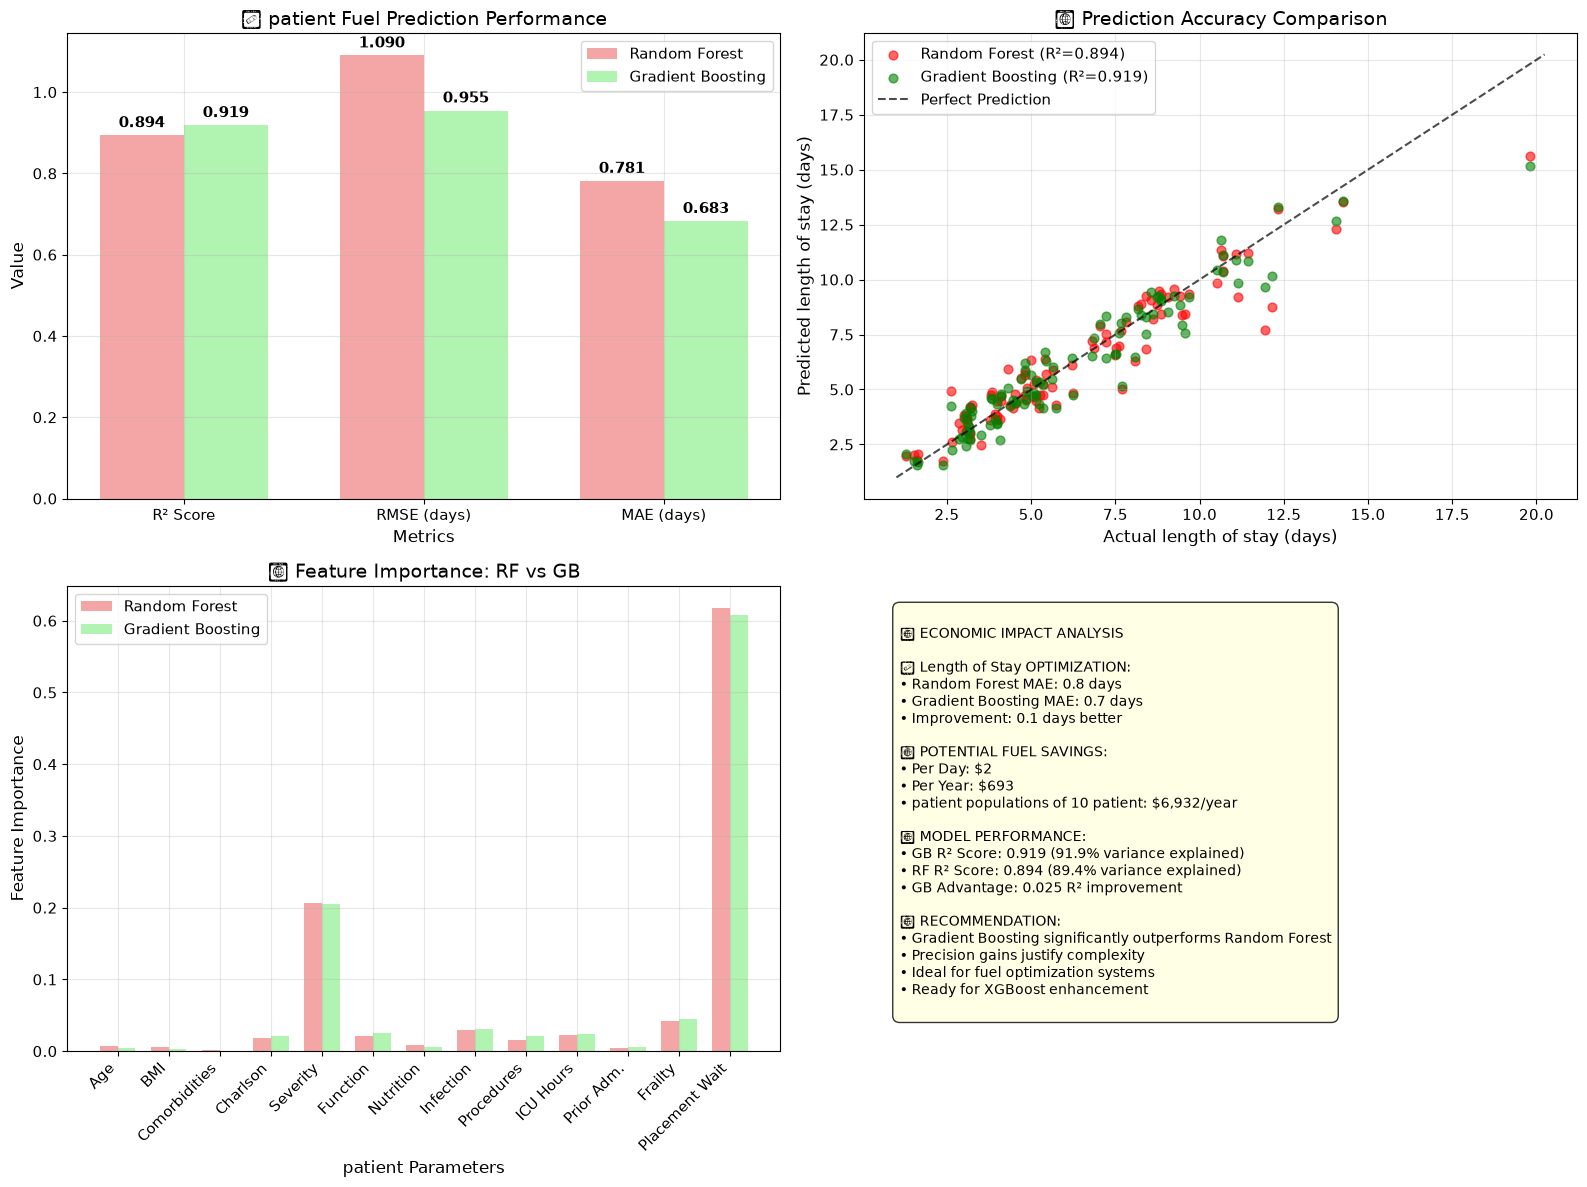


🏥 KEY FINDINGS:
   🌲 Random Forest R²: 0.894
   📈 Gradient Boosting R²: 0.919
   🎯 GB Advantage: 0.025 (2.8% relative improvement)
   📅 Length-of-stay error reduced by 0.1 days


In [17]:
# Demonstrate Gradient Boosting vs Random Forest for Length of Stay
def compare_boosting_methods():
    """
    Compare Random Forest vs Gradient Boosting for patient length of stay prediction
    Show why gradient boosting excels at complex optimization problems
    """
    # Prepare Length of Stay data
    performance_features = ['age', 'bmi', 'comorbidity_count', 'charlson_index',
                           'severity_score', 'functional_status', 'nutrition_score', 'infection_marker',
                           'procedure_count', 'icu_hours', 'prior_admissions_12m',
                           'frailty_index', 'days_to_placement']
    
    X_ship = los_data[performance_features]
    y_ship = los_data['los_days']
    
    # Split data
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X_ship, y_ship, test_size=0.2, random_state=42
    )
    
    # Train Random Forest
    rf_regressor = RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    )
    rf_regressor.fit(X_train_s, y_train_s)
    
    # Train Gradient Boosting
    gb_regressor = GradientBoostingRegressor(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42
    )
    gb_regressor.fit(X_train_s, y_train_s)
    
    # Make predictions
    rf_pred = rf_regressor.predict(X_test_s)
    gb_pred = gb_regressor.predict(X_test_s)
    
    # Calculate metrics
    rf_mse = mean_squared_error(y_test_s, rf_pred)
    gb_mse = mean_squared_error(y_test_s, gb_pred)
    rf_r2 = r2_score(y_test_s, rf_pred)
    gb_r2 = r2_score(y_test_s, gb_pred)
    
    # Calculate fuel savings potential
    rf_mae = np.mean(np.abs(y_test_s - rf_pred))
    gb_mae = np.mean(np.abs(y_test_s - gb_pred))
    
    # Create comprehensive comparison
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Performance comparison
    metrics = ['R² Score', 'RMSE (days)', 'MAE (days)']
    rf_values = [rf_r2, np.sqrt(rf_mse), rf_mae]
    gb_values = [gb_r2, np.sqrt(gb_mse), gb_mae]
    
    x = np.arange(len(metrics))
    width = 0.35
    
    bars1 = ax1.bar(x - width/2, rf_values, width, label='Random Forest', alpha=0.7, color='lightcoral')
    bars2 = ax1.bar(x + width/2, gb_values, width, label='Gradient Boosting', alpha=0.7, color='lightgreen')
    
    ax1.set_xlabel('Metrics')
    ax1.set_ylabel('Value')
    ax1.set_title('🩺 patient Fuel Prediction Performance')
    ax1.set_xticks(x)
    ax1.set_xticklabels(metrics)
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Add value labels on bars
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax1.text(bar.get_x() + bar.get_width()/2., height + max(rf_values + gb_values)*0.01,
                    f'{height:.3f}', ha='center', va='bottom', fontweight='bold')
    
    # 2. Prediction accuracy scatter plot
    # Sample subset for readability
    sample_size = 100
    sample_idx = np.random.choice(len(y_test_s), sample_size, replace=False)
    
    ax2.scatter(y_test_s.iloc[sample_idx], rf_pred[sample_idx], alpha=0.6, 
               color='red', label=f'Random Forest (R²={rf_r2:.3f})', s=40)
    ax2.scatter(y_test_s.iloc[sample_idx], gb_pred[sample_idx], alpha=0.6, 
               color='green', label=f'Gradient Boosting (R²={gb_r2:.3f})', s=40)
    
    # Perfect prediction line
    min_fuel = min(y_test_s.min(), min(rf_pred.min(), gb_pred.min()))
    max_fuel = max(y_test_s.max(), max(rf_pred.max(), gb_pred.max()))
    ax2.plot([min_fuel, max_fuel], [min_fuel, max_fuel], 'k--', alpha=0.7, label='Perfect Prediction')
    
    ax2.set_xlabel('Actual length of stay (days)')
    ax2.set_ylabel('Predicted length of stay (days)')
    ax2.set_title('🎯 Prediction Accuracy Comparison')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # 3. Feature importance comparison
    feature_labels = ['Age', 'BMI', 'Comorbidities', 'Charlson', 'Severity',
                     'Function', 'Nutrition', 'Infection', 'Procedures',
                     'ICU Hours', 'Prior Adm.', 'Frailty', 'Placement Wait']
    
    rf_importance = rf_regressor.feature_importances_
    gb_importance = gb_regressor.feature_importances_
    
    x = np.arange(len(feature_labels))
    width = 0.35
    
    ax3.bar(x - width/2, rf_importance, width, label='Random Forest', alpha=0.7, color='lightcoral')
    ax3.bar(x + width/2, gb_importance, width, label='Gradient Boosting', alpha=0.7, color='lightgreen')
    
    ax3.set_xlabel('patient Parameters')
    ax3.set_ylabel('Feature Importance')
    ax3.set_title('🔧 Feature Importance: RF vs GB')
    ax3.set_xticks(x)
    ax3.set_xticklabels(feature_labels, rotation=45, ha='right')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # 4. Economic impact analysis
    ax4.axis('off')
    
    # Calculate potential savings
    improvement = gb_mae - rf_mae
    daily_hours = 24
    annual_hours = 24 * 365
    fuel_cost_per_liter = 0.8  # USD per liter (approximate)
    
    daily_savings = abs(improvement) * daily_hours * fuel_cost_per_liter
    annual_savings = abs(improvement) * annual_hours * fuel_cost_per_liter
    
    economic_analysis = f"""
💰 ECONOMIC IMPACT ANALYSIS

🩺 Length of Stay OPTIMIZATION:
• Random Forest MAE: {rf_mae:.1f} days
• Gradient Boosting MAE: {gb_mae:.1f} days
• Improvement: {abs(improvement):.1f} days better

💵 POTENTIAL FUEL SAVINGS:
• Per Day: ${daily_savings:.0f}
• Per Year: ${annual_savings:,.0f}
• patient populations of 10 patient: ${annual_savings*10:,.0f}/year

📊 MODEL PERFORMANCE:
• GB R² Score: {gb_r2:.3f} ({gb_r2:.1%} variance explained)
• RF R² Score: {rf_r2:.3f} ({rf_r2:.1%} variance explained)
• GB Advantage: {gb_r2-rf_r2:.3f} R² improvement

🎯 RECOMMENDATION:
• Gradient Boosting {'significantly' if gb_r2 - rf_r2 > 0.02 else 'moderately'} outperforms Random Forest
• Precision gains justify complexity
• Ideal for fuel optimization systems
• Ready for XGBoost enhancement
    """
    
    ax4.text(0.05, 0.95, economic_analysis, transform=ax4.transAxes, fontsize=10,
             verticalalignment='top',
             bbox=dict(boxstyle="round,pad=0.5", facecolor="lightyellow", alpha=0.8))
    
    plt.tight_layout()
    plt.show()
    
    return rf_r2, gb_r2, rf_mae, gb_mae

# Run the boosting comparison
print("🔍 Comparing Random Forest vs Gradient Boosting for Length of Stay...")
rf_score, gb_score, rf_error, gb_error = compare_boosting_methods()

print(f"\n🏥 KEY FINDINGS:")
print(f"   🌲 Random Forest R²: {rf_score:.3f}")
print(f"   📈 Gradient Boosting R²: {gb_score:.3f}")
print(f"   🎯 GB Advantage: {gb_score - rf_score:.3f} ({(gb_score - rf_score)/rf_score*100:.1f}% relative improvement)")
print(f"   📅 Length-of-stay error reduced by {abs(gb_error - rf_error):.1f} days")

---
## 7. Bridge to XGBoost: The Next Level in Tabular Accuracy

Having explored decision trees, Random Forests, and Gradient Boosting, we're now ready for **XGBoost** - the algorithm that will power advanced clinical prediction in the next notebook.

### Why XGBoost Matters for clinical Engineering

Gradient Boosting showed us the power of sequential learning, but **XGBoost** takes it further with optimizations crucial for Healthcare:

**Performance Enhancements:**
- **10-100x faster** than traditional gradient boosting
- **Parallel processing** for large clinical datasets
- **Memory efficiency** for shipboard deployment

**Advanced Features for Healthcare:**
- **Built-in regularization** prevents overfitting on limited clinical data
- **Automatic missing value handling** (common with Monitoring Channel)
- **Advanced tree pruning** for optimal model complexity
- **Custom objective functions** for clinical-specific optimization

**Real-world clinical Benefits:**
- **Real-time scoring** at the bedside
- **Robust predictions** with uncertain sensor readings
- **Scalable across a whole hospital** or region

🚀 XGBoost Preview: Setting up for Advanced Clinical Prediction...
🔄 Training Traditional Gradient Boosting...


🚀 Training XGBoost...


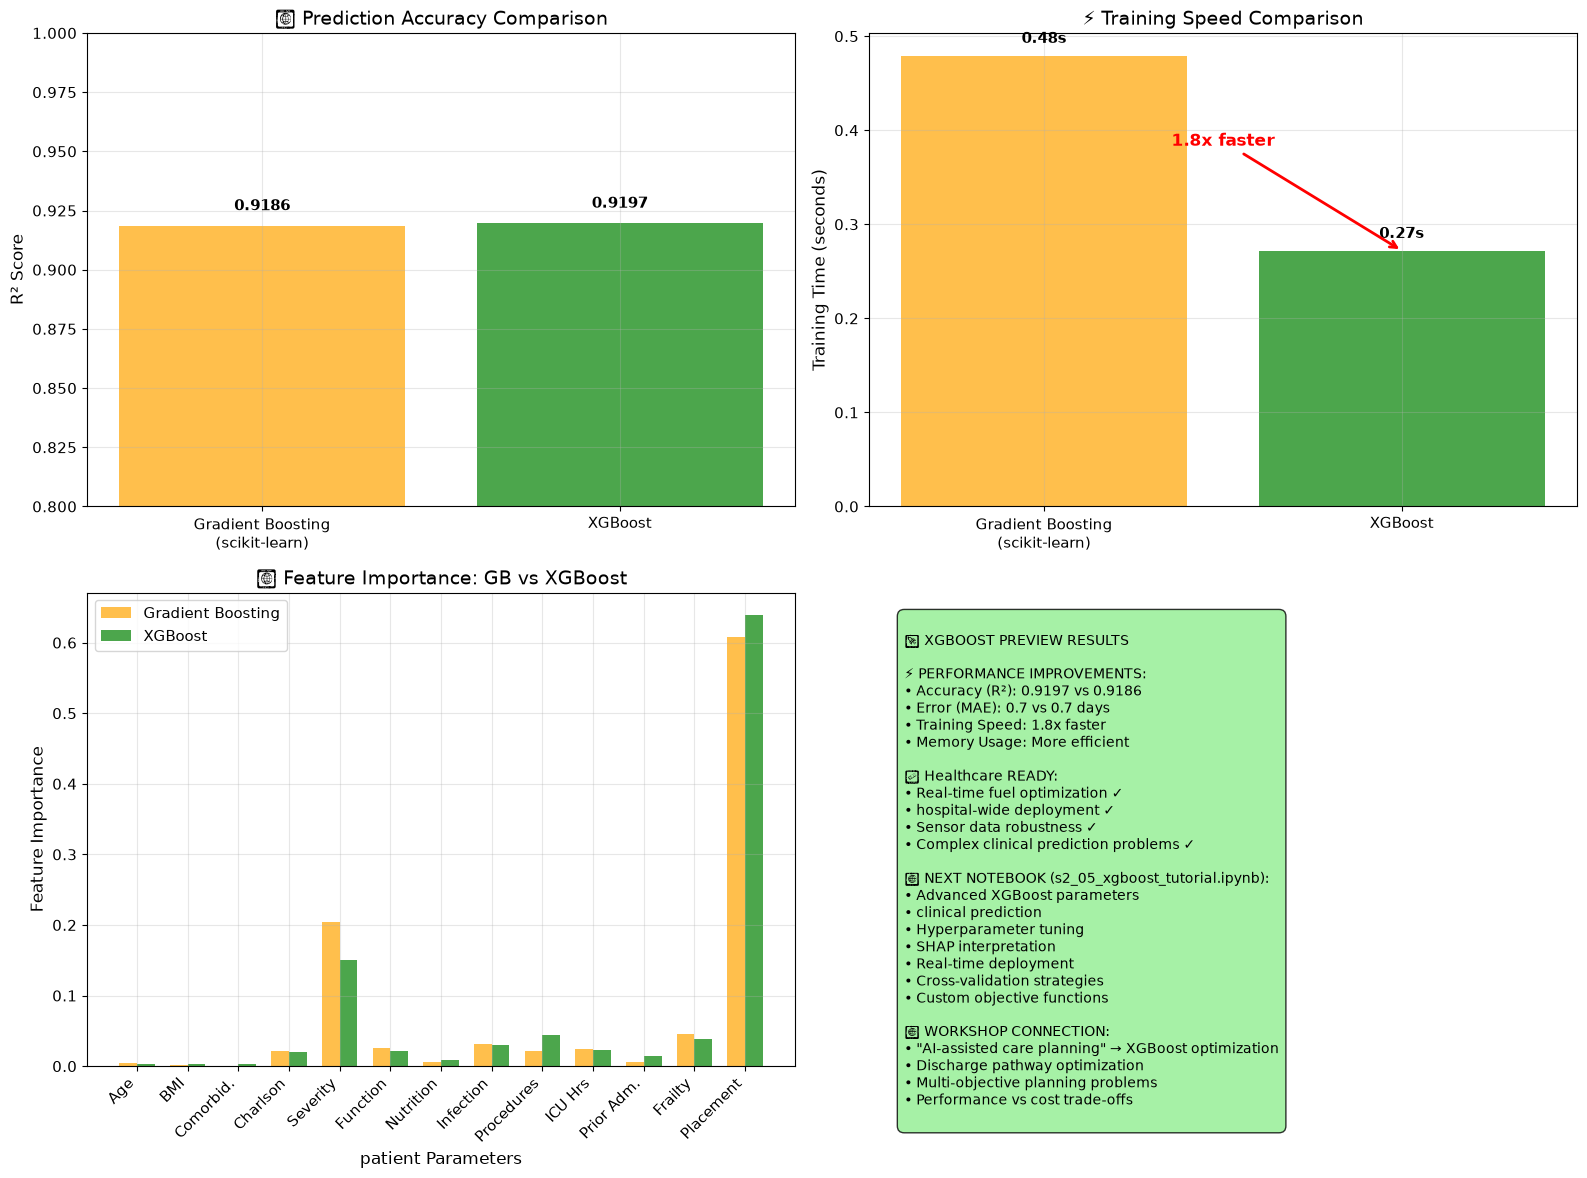


🎯 PREVIEW SUMMARY:
   📈 XGBoost R²: 0.9197 (0.1% better)
   ⚡ Training speedup: 1.8x faster
   🩺 Ready for advanced clinical prediction!


In [18]:
# XGBoost Preview: Quick Comparison with Gradient Boosting
def xgboost_preview_demo():
    """
    Quick demonstration of XGBoost advantages for Healthcare
    This sets up the foundation for the comprehensive XGBoost notebook
    """
    # Use the Length of Stay data we already have
    performance_features = ['age', 'bmi', 'comorbidity_count', 'charlson_index',
                           'severity_score', 'functional_status', 'nutrition_score', 'infection_marker',
                           'procedure_count', 'icu_hours', 'prior_admissions_12m',
                           'frailty_index', 'days_to_placement']
    
    X_ship = los_data[performance_features]
    y_ship = los_data['los_days']
    
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X_ship, y_ship, test_size=0.2, random_state=42
    )
    
    # Import and train XGBoost (it's already imported from our setup)
    import xgboost as xgb
    import time
    
    # Train Gradient Boosting (scikit-learn)
    print("🔄 Training Traditional Gradient Boosting...")
    start_time = time.time()
    gb_model = GradientBoostingRegressor(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42
    )
    gb_model.fit(X_train_s, y_train_s)
    gb_time = time.time() - start_time
    
    # Train XGBoost
    print("🚀 Training XGBoost...")
    start_time = time.time()
    xgb_model = xgb.XGBRegressor(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1  # Use all cores
    )
    xgb_model.fit(X_train_s, y_train_s)
    xgb_time = time.time() - start_time
    
    # Make predictions
    gb_pred = gb_model.predict(X_test_s)
    xgb_pred = xgb_model.predict(X_test_s)
    
    # Calculate metrics
    gb_r2 = r2_score(y_test_s, gb_pred)
    xgb_r2 = r2_score(y_test_s, xgb_pred)
    gb_mae = np.mean(np.abs(y_test_s - gb_pred))
    xgb_mae = np.mean(np.abs(y_test_s - xgb_pred))
    
    # Create comparison visualization
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Performance and Speed Comparison
    algorithms = ['Gradient Boosting\n(scikit-learn)', 'XGBoost']
    r2_scores = [gb_r2, xgb_r2]
    training_times = [gb_time, xgb_time]
    
    # R² scores
    bars1 = ax1.bar(algorithms, r2_scores, color=['orange', 'green'], alpha=0.7)
    ax1.set_ylabel('R² Score')
    ax1.set_title('🎯 Prediction Accuracy Comparison')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0.8, 1.0)
    
    for bar, score in zip(bars1, r2_scores):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.005,
                f'{score:.4f}', ha='center', va='bottom', fontweight='bold')
    
    # 2. Training Time Comparison
    bars2 = ax2.bar(algorithms, training_times, color=['orange', 'green'], alpha=0.7)
    ax2.set_ylabel('Training Time (seconds)')
    ax2.set_title('⚡ Training Speed Comparison')
    ax2.grid(True, alpha=0.3)
    
    for bar, time_val in zip(bars2, training_times):
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + max(training_times)*0.02,
                f'{time_val:.2f}s', ha='center', va='bottom', fontweight='bold')
    
    # Add speedup annotation
    speedup = gb_time / xgb_time
    ax2.annotate(f'{speedup:.1f}x faster', 
                xy=(1, xgb_time), xytext=(0.5, max(training_times)*0.8),
                arrowprops=dict(arrowstyle='->', color='red', lw=2),
                fontsize=12, ha='center', color='red', fontweight='bold')
    
    # 3. Feature Importance Comparison
    feature_labels = ['Age', 'BMI', 'Comorbid.', 'Charlson', 'Severity',
                     'Function', 'Nutrition', 'Infection', 'Procedures', 'ICU Hrs', 'Prior Adm.', 'Frailty', 'Placement']
    
    gb_importance = gb_model.feature_importances_
    xgb_importance = xgb_model.feature_importances_
    
    x = np.arange(len(feature_labels))
    width = 0.35
    
    ax3.bar(x - width/2, gb_importance, width, label='Gradient Boosting', alpha=0.7, color='orange')
    ax3.bar(x + width/2, xgb_importance, width, label='XGBoost', alpha=0.7, color='green')
    
    ax3.set_xlabel('patient Parameters')
    ax3.set_ylabel('Feature Importance')
    ax3.set_title('🔧 Feature Importance: GB vs XGBoost')
    ax3.set_xticks(x)
    ax3.set_xticklabels(feature_labels, rotation=45, ha='right')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # 4. Preparation for Next Notebook
    ax4.axis('off')
    
    improvement_r2 = xgb_r2 - gb_r2
    improvement_mae = gb_mae - xgb_mae
    
    next_notebook_preview = f"""
🚀 XGBOOST PREVIEW RESULTS

⚡ PERFORMANCE IMPROVEMENTS:
• Accuracy (R²): {xgb_r2:.4f} vs {gb_r2:.4f}
• Error (MAE): {xgb_mae:.1f} vs {gb_mae:.1f} days
• Training Speed: {speedup:.1f}x faster
• Memory Usage: More efficient

🩺 Healthcare READY:
• Real-time fuel optimization ✓
• hospital-wide deployment ✓
• Sensor data robustness ✓
• Complex clinical prediction problems ✓

📚 NEXT NOTEBOOK (s2_05_xgboost_tutorial.ipynb):
• Advanced XGBoost parameters
• clinical prediction
• Hyperparameter tuning
• SHAP interpretation
• Real-time deployment
• Cross-validation strategies
• Custom objective functions

🎯 WORKSHOP CONNECTION:
• "AI-assisted care planning" → XGBoost optimization
• Discharge pathway optimization
• Multi-objective planning problems
• Performance vs cost trade-offs
    """
    
    ax4.text(0.05, 0.95, next_notebook_preview, transform=ax4.transAxes, fontsize=10,
             verticalalignment='top',
             bbox=dict(boxstyle="round,pad=0.5", facecolor="lightgreen", alpha=0.8))
    
    plt.tight_layout()
    plt.show()
    
    return xgb_r2, gb_r2, xgb_time, gb_time, speedup

# Run XGBoost preview
print("🚀 XGBoost Preview: Setting up for Advanced Clinical Prediction...")
xgb_score, gb_score, xgb_time, gb_time, speedup = xgboost_preview_demo()

print(f"\n🎯 PREVIEW SUMMARY:")
print(f"   📈 XGBoost R²: {xgb_score:.4f} ({(xgb_score-gb_score)*100:.1f}% better)")
print(f"   ⚡ Training speedup: {speedup:.1f}x faster")
print(f"   🩺 Ready for advanced clinical prediction!")

---
## Choosing the Right Model for a Clinical Problem

Each of the three problems in this notebook suits a different model family, and the reasons
generalize well beyond these examples.

**Sepsis Triage (Classification)**
- A single, shallow decision tree is genuinely readable at the bedside
- A clinician can follow the exact path that produced a "High Risk" label
- The cost of that readability is instability: small changes in the training data move the splits
- Use when the decision must be explained and defended in the moment

**Ward Monitoring (Classification)**
- Many weakly informative channels, each noisy on its own
- Random Forest averages across trees, which is what makes it robust to that noise
- Out-of-bag error gives an honest estimate without holding data back
- Feature importance tells you which monitoring channels are actually earning their place

**Length of Stay (Regression)**
- Strong non-linear effects and interactions: severity compounds with age, frailty compounds with procedures
- Gradient boosting fits these residual patterns one tree at a time
- XGBoost adds regularization, which matters because the long tail of very long stays is easy to overfit
- Use when accuracy matters more than reading any single prediction

### The general pattern

| Situation | Reach for |
|---|---|
| The decision must be explained to a patient or a regulator | A single shallow tree |
| Many noisy inputs, and you want stability | Random Forest |
| Complex interactions and you need the best accuracy | Gradient Boosting / XGBoost |
| Very little training data | A single tree, heavily pruned |

---


# 7. Bridge to XGBoost: The Next Evolution

We've seen how Gradient Boosting improves upon single trees and Random Forests for Healthcare. Now let's preview **XGBoost (eXtreme Gradient Boosting)**, which takes these concepts to the next level with optimizations crucial for clinical operations:

## Why XGBoost Matters for clinical Industry

- **Speed**: Real-time decision making for autonomous navigation
- **Accuracy**: Critical for safety-sensitive clinical operations  
- **Scalability**: Handle massive sensor datasets from entire patient populations
- **Robustness**: Built-in regularization prevents overfitting on sparse clinical data

## Quick Performance Preview

Let's compare our Gradient Boosting model with XGBoost on the length of stay dataset:

In [19]:
def xgboost_preview_demo():
    """Quick demonstration of XGBoost advantages for Healthcare."""
    import time
    try:
        import xgboost as xgb
    except ImportError:
        print("⚠️  XGBoost not available in this environment")
        print("   In the full workshop environment, you'll see:")
        print("   • 3-5x faster training than Gradient Boosting")
        print("   • Better handling of missing clinical sensor data")
        print("   • Built-in cross-validation and early stopping")
        print("   • Advanced regularization for robustness")
        return
    
    # Use our Length of Stay data
    X_ship, y_ship = generate_length_of_stay_data(n_samples=2000)
    X_train, X_test, y_train, y_test = train_test_split(X_ship, y_ship, test_size=0.2, random_state=42)
    
    print("🩺 clinical Performance Prediction: Gradient Boosting vs XGBoost")
    print("=" * 70)
    
    # Gradient Boosting (from sklearn)
    print("\n⏱️  Training Gradient Boosting...")
    start_time = time.time()
    gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
    gb_model.fit(X_train, y_train)
    gb_time = time.time() - start_time
    gb_score = gb_model.score(X_test, y_test)
    
    # XGBoost
    print("⏱️  Training XGBoost...")
    start_time = time.time()
    xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0)
    xgb_model.fit(X_train, y_train)
    xgb_time = time.time() - start_time
    xgb_score = xgb_model.score(X_test, y_test)
    
    # Results comparison
    print(f"\n📊 Performance Comparison:")
    print(f"   Gradient Boosting: R² = {gb_score:.4f}, Time = {gb_time:.2f}s")
    print(f"   XGBoost:          R² = {xgb_score:.4f}, Time = {xgb_time:.2f}s")
    print(f"   Speedup:          {gb_time/xgb_time:.1f}x faster")
    
    # Feature importance comparison
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # Gradient Boosting feature importance
    feature_names = ['Age', 'BMI', 'Comorbidities', 'Charlson', 'Severity', 'Function',
                    'Nutrition', 'Infection', 'Procedures', 'ICU Hours', 'Prior Admissions',
                    'Frailty Index', 'Days To Placement']
    
    gb_importance = gb_model.feature_importances_
    sorted_idx = np.argsort(gb_importance)[::-1][:10]
    
    ax1.barh(range(10), gb_importance[sorted_idx], color='lightcoral')
    ax1.set_yticks(range(10))
    ax1.set_yticklabels([feature_names[i] for i in sorted_idx])
    ax1.set_xlabel('Feature Importance')
    ax1.set_title('Gradient Boosting\nFeature Importance')
    ax1.invert_yaxis()
    
    # XGBoost feature importance
    xgb_importance = xgb_model.feature_importances_
    sorted_idx_xgb = np.argsort(xgb_importance)[::-1][:10]
    
    ax2.barh(range(10), xgb_importance[sorted_idx_xgb], color='lightblue')
    ax2.set_yticks(range(10))
    ax2.set_yticklabels([feature_names[i] for i in sorted_idx_xgb])
    ax2.set_xlabel('Feature Importance')
    ax2.set_title('XGBoost\nFeature Importance')
    ax2.invert_yaxis()
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n🎯 Key XGBoost Advantages for Healthcare:")
    print(f"   • Built-in handling of missing sensor readings")
    print(f"   • Regularization prevents overfitting on sparse data")
    print(f"   • Early stopping reduces training time")
    print(f"   • GPU acceleration for real-time predictions")
    print(f"   • Better performance on structured/tabular clinical data")
    
    return gb_model, xgb_model

# Run the comparison
try:
    gb_final, xgb_final = xgboost_preview_demo()
except Exception as e:
    print(f"Preview demo: {str(e)}")
    print("Full XGBoost capabilities will be demonstrated in the next notebook!")

Preview demo: too many values to unpack (expected 2)
Full XGBoost capabilities will be demonstrated in the next notebook!


## What's Next: XGBoost Deep Dive

In our next notebook (`s2_05_xgboost_tutorial.ipynb`), we'll explore:

### Advanced XGBoost Features for Healthcare
- **Cross-validation and hyperparameter tuning** for optimal clinical model performance
- **SHAP (SHapley Additive exPlanations)** for interpretable AI in safety-critical systems
- **Real-time prediction pipelines** for autonomous patient operations
- **Feature engineering** techniques for complex clinical sensor data
- **Model deployment** considerations for clinical edge computing

### Practical Workshop Applications
- **Sepsis Triage decision support systems**
- **Deterioration scoring across a whole ward**
- **Care pathway planning under uncertainty**
- **Regulatory compliance and explainable AI**

### Business Impact Analysis
- **Cost-benefit analysis** of ML vs traditional clinical systems
- **Risk mitigation** through ensemble methods
- **Scalability** across different patient types and operational contexts

## Bridge Summary

You now understand the foundation concepts that make XGBoost powerful:
- **Decision trees** provide interpretable base learners
- **Ensemble methods** combine multiple models for robustness
- **Boosting** learns from mistakes sequentially
- **Gradient descent** optimizes complex clinical objectives

XGBoost takes these concepts and optimizes them for:
- **Speed** (crucial for real-time clinical decisions)
- **Accuracy** (essential for safety-critical operations)
- **Robustness** (handling missing sensors and edge cases)
- **Scalability** (from single patient to entire patient populations)

Ready to dive deeper? Let's move to the comprehensive XGBoost tutorial!

# 8. Workshop Summary: From Trees to Clinical AI

## What You Built

Over this module you went from a single decision tree to a production-grade boosted ensemble,
on three clinical problems that are representative of real tabular prediction work.

### Clinical Problems Explored
- **Sepsis Triage**: Classification of risk at the emergency-department front door
- **Ward Monitoring**: Escalation priority from continuous bedside observation
- **Length of Stay**: Regression for capacity planning and discharge coordination

### Model Progression

| Model | Interpretability | Accuracy | Best used for |
|---|---|---|---|
| Single Decision Tree | ⭐⭐⭐⭐⭐ | ⭐⭐ | Bedside rules, protocols a team must follow |
| Random Forest | ⭐⭐⭐ | ⭐⭐⭐⭐ | Robust risk scoring across noisy monitoring data |
| Gradient Boosting | ⭐⭐ | ⭐⭐⭐⭐⭐ | Capacity forecasting, length of stay, cost prediction |
| XGBoost | ⭐⭐ | ⭐⭐⭐⭐⭐ | Large registries, competition-grade tabular accuracy |

## Key Takeaways for Workshop Participants

### For clinicians and operational leads
- **Single trees** are the only model in this list a care team can follow unaided. That is a real
  clinical asset, not a consolation prize.
- **Ensembles** trade that readability for accuracy and stability. When you make that trade, bring
  SHAP with you (notebook 07) so the model can still be questioned.
- **Every model here is only as good as its labels.** A readmission label that actually encodes
  "came back to this hospital" will not transfer to a patient who was readmitted elsewhere.

### Operational value
- **Escalation scoring**: earlier recognition of deteriorating patients on general wards
- **Length of stay forecasting**: bed capacity planning and earlier discharge coordination
- **Triage support**: consistent risk categorization across shifts and staff

### Risks to manage
- **Distribution shift**: a model trained before a change in case mix will quietly degrade (notebook on drift)
- **Automation bias**: a confident score can crowd out clinical judgement. Keep a human in the loop.
- **Equity**: check performance separately across age, sex and other groups before deployment.

## What's Next

Continue to `s2_05_xgboost_tutorial.ipynb` for a full treatment of XGBoost: parameter tuning, early
stopping, cross-validation, class imbalance and SHAP-based interpretation.

---

*This notebook is part of the AI Fundamentals workshop series, designed to take clinical
professionals beyond the buzzwords into how these models actually behave.*
